# COURSE PROJECT: PROGRAMMING FOUNDATIONS FOR DATA ANALYSIS AND VISUALIZATION
**Semester 261 – Academic Year 2026–2027** | **Instructor:** Lê Thành Sách

---
## PART 3: TIME SERIES DATA
### Topic: 24-Hour-Ahead PM2.5 Forecasting — Hanoi vs Ho Chi Minh City

- **Group:** IndexError
- **Member in charge:** Nguyễn Văn Hoàng Khang – 2570754

**Problem.** At time $t$, using the PM2.5 history and the current weather, forecast the PM2.5 concentration
at time $t + 24h$ (the same hour tomorrow). This is a **time series regression** problem.

**Why compare two cities?** Hanoi (four seasons, winter temperature inversion) and Ho Chi Minh City (HCMC; wet/dry seasons)
have different pollution mechanisms. We apply **the same pipeline** to each city **independently** (no merging) to answer:
*how much does machine learning improve over a naive baseline in each city, and which city is harder to forecast?*

## 0. ENVIRONMENT SETUP

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

RANDOM_STATE = 42
HORIZON = 24            # forecast 24 hours ahead
WHO_24H = 15            # WHO 2021 guideline for 24-hour mean PM2.5 (µg/m³)
CITY_COLORS = {'Hanoi': '#d62728', 'HCMC': '#1f77b4'}
import sklearn
print(f'Environment ready! (scikit-learn {sklearn.__version__}, pandas {pd.__version__})')

Environment ready! (scikit-learn 1.9.1, pandas 3.0.5)


## 1. DATASET DESCRIPTION

### 1.1. Data sources (self-collected)
The data was **collected through public APIs** with the script `scripts/crawl_air_quality.py`:

| Component | Source | Notes |
|---|---|---|
| PM2.5 – Hanoi | [OpenAQ v3](https://openaq.org) – station *Công viên Nhân Chính – Khuất Duy Tiến* (Hanoi Air Quality Monitoring Network, sensor 13502151) | Reference monitor of the city network |
| PM2.5 – HCMC | OpenAQ v3 – station *CMT8* (AirGradient, sensor 11357424) | Low-cost sensor (the only HCMC station with continuous data in the period) |
| Weather | [Open-Meteo Historical Weather API](https://open-meteo.com) | Temperature, humidity, precipitation, wind, pressure, cloud cover, at the coordinates of each PM2.5 station |

- **PM2.5 values** are OpenAQ hourly means of the station's sub-hourly readings; each timestamp is the **start** of the hour, Vietnam local time (UTC+7).
- **Period:** the same calendar period for both cities, from the first full day of the Hanoi station to the last full day before the crawl
  (exact dates and number of hours are printed in Section 1.2).
- A complete hourly time grid is built: hours with no measurement become `NaN`.

**How the stations were chosen.** The script `scripts/check_station_coverage.py` lists every OpenAQ PM2.5 sensor within 25 km of
each city centre that reported during the period and measures, over the period: `coverage` (share of hours with a value),
`worst_hour_cov` (lowest coverage among the 24 hours of the day), `worst_month_cov` (lowest coverage among calendar months) and
`longest_gap_h` (longest run of missing hours). `worst_hour_cov` matters as much as `coverage`: if a station misses mostly the
afternoon hours, the gaps are **not at random** (the missing hours differ systematically from the measured ones) and both the
daily cycle and the forecast errors would be biased. We use the station with the highest coverage in each city.

| Column | Type | Meaning |
|---|---|---|
| `datetime` | datetime | Timestamp (local time, start of the hour) |
| `city` | categorical | City |
| `temperature_2m` | numerical | Temperature at 2 m (°C) |
| `relative_humidity_2m` | numerical | Relative humidity (%) |
| `precipitation` | numerical | Precipitation (mm) |
| `wind_speed_10m` | numerical | Wind speed at 10 m (km/h) |
| `wind_direction_10m` | numerical (angle) | Wind direction (degrees) → converted to a **categorical** 8-sector feature |
| `surface_pressure` | numerical | Surface pressure (hPa) |
| `cloud_cover` | numerical | Cloud cover (%) |
| `pm25` | numerical | PM2.5 concentration (µg/m³) — **the variable to forecast** |
| `pm25_source` | categorical | PM2.5 source (`openaq`, or `open-meteo` if the crawler had to fall back) |
| `station` | categorical | Name of the PM2.5 station |

### 1.2. Loading the data
The CSV files are read locally; on Colab, if they are not found, they are downloaded from GitHub (**set `GITHUB_RAW_BASE`** to the group's repo).

In [2]:
GITHUB_RAW_BASE = 'https://raw.githubusercontent.com/perckgg/NTLT/main/03_TimeSeries/data/timeseries'
CITY_FILES = {'Hanoi': 'air_quality_hanoi.csv', 'HCMC': 'air_quality_hcmc.csv'}
LOCAL_DIRS = ['data/timeseries', '../data/timeseries', '/content/data/timeseries', '/content']


def load_csv(filename, parse_dates=('datetime',)):
    """Read a CSV from the first local folder that has it, otherwise from GitHub."""
    for d in LOCAL_DIRS:
        path = os.path.join(d, filename)
        if os.path.exists(path):
            return pd.read_csv(path, parse_dates=list(parse_dates))
    return pd.read_csv(f'{GITHUB_RAW_BASE}/{filename}', parse_dates=list(parse_dates))


raw = {city: load_csv(f).set_index('datetime').sort_index().assign(city=city)
       for city, f in CITY_FILES.items()}
for city, df in raw.items():
    print(f'{city}: {df.shape[0]:,} rows × {df.shape[1]} columns | '
          f'{df.index.min():%Y-%m-%d %H:%M} → {df.index.max():%Y-%m-%d %H:%M} '
          f'({(df.index.max() - df.index.min()).days + 1} days) | station: {", ".join(df.station.unique())} | '
          f'PM2.5 source: {", ".join(df.pm25_source.unique())}')

coverage = load_csv('station_coverage.csv', parse_dates=('first', 'last'))
print('\nCandidate stations over the same period (output of scripts/check_station_coverage.py):')
display(coverage)
raw['Hanoi'].head()

Hanoi: 11,976 rows × 11 columns | 2025-07-04 00:00 → 2026-11-14 23:00 (499 days) | station: Nhan Chinh - Khuat Duy Tien | PM2.5 source: openaq
HCMC: 11,976 rows × 11 columns | 2025-07-04 00:00 → 2026-11-14 23:00 (499 days) | station: CMT8 | PM2.5 source: openaq

Candidate stations over the same period (output of scripts/check_station_coverage.py):


,city,station,sensor_id,type,coverage,worst_hour_cov,worst_month_cov,longest_gap_h,first,last
0,HCMC,CMT8 (AirGradient),11357424,low-cost,0.994,0.982,0.965,8,2025-07-04 00:00:00,2026-11-14 22:00:00
1,Hanoi,Cong vien Nhan Chinh - Khuat Duy Tien,13502151,reference,0.964,0.950,0.721,86,2025-07-04 00:00:00,2026-11-14 22:00:00
2,Hanoi,Giai Phong - DH Bach Khoa,13502154,reference,0.928,0.892,0.788,136,2025-07-04 00:00:00,2026-11-14 22:00:00
3,Hanoi,Dragon (AirGradient),14581375,low-cost,0.723,0.711,0.000,3060,2025-11-08 12:00:00,2026-11-14 22:00:00
4,Hanoi,556 Nguyen Van Cu,13502150,reference,0.653,0.621,0.000,2934,2025-07-04 00:00:00,2026-07-15 17:00:00
5,Hanoi,46 Luu Quang Vu,7772032,reference,0.510,0.279,0.026,859,2025-07-04 00:00:00,2026-11-13 08:00:00
6,Hanoi,Minh Khai - Bac Tu Liem,7772087,reference,0.148,0.016,0.000,3849,2025-08-07 11:00:00,2026-11-13 08:00:00


,city,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover,pm25,pm25_source,station
datetime,,,,,,,,,,,
2025-07-04 00:00:00,Hanoi,25.2,98,0.0,2.8,315,1006.0,100,21.6,openaq,Nhan Chinh - Khuat Duy Tien
2025-07-04 01:00:00,Hanoi,25.1,98,0.0,2.8,349,1005.5,100,27.7,openaq,Nhan Chinh - Khuat Duy Tien
2025-07-04 02:00:00,Hanoi,25.1,97,0.0,3.5,325,1004.9,100,27.3,openaq,Nhan Chinh - Khuat Duy Tien
2025-07-04 03:00:00,Hanoi,25.0,97,0.0,4.6,321,1004.6,100,23.7,openaq,Nhan Chinh - Khuat Duy Tien
2025-07-04 04:00:00,Hanoi,24.9,97,0.0,5.2,344,1004.6,100,25.5,openaq,Nhan Chinh - Khuat Duy Tien


### 1.3. Descriptive statistics
The WHO guideline of 15 µg/m³ is defined for the **24-hour mean**, so it is compared with **daily means**, not with single hours.
A daily mean is computed only for days with at least 18 of 24 hours measured (75% completeness, the usual rule for daily averages);
other days are left out rather than averaged over a few hours.

In [3]:
MIN_HOURS_PER_DAY = 18   # 75% of 24 hours


def daily_means(s, min_hours=MIN_HOURS_PER_DAY):
    """Daily mean of an hourly series; NaN for days with fewer than `min_hours` measured hours."""
    days = s.resample('D')
    return days.mean().where(days.count() >= min_hours)


raw['Hanoi'].info()
summary = pd.concat({city: df['pm25'].describe() for city, df in raw.items()}, axis=1).T
summary['missing_rate'] = [df['pm25'].isna().mean() for df in raw.values()]
daily = {city: daily_means(df['pm25']).dropna() for city, df in raw.items()}
summary['valid days'] = [len(d) for d in daily.values()]
summary['share of days > WHO 24h'] = [(d > WHO_24H).mean() for d in daily.values()]
display(summary.round(3))
display(pd.concat({city: df.describe().T for city, df in raw.items()}).round(2))

<class 'pandas.DataFrame'>
DatetimeIndex: 11976 entries, 2025-07-04 00:00:00 to 2026-11-14 23:00:00
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   city                  11976 non-null  str    
 1   temperature_2m        11976 non-null  float64
 2   relative_humidity_2m  11976 non-null  int64  
 3   precipitation         11976 non-null  float64
 4   wind_speed_10m        11976 non-null  float64
 5   wind_direction_10m    11976 non-null  int64  
 6   surface_pressure      11976 non-null  float64
 7   cloud_cover           11976 non-null  int64  
 8   pm25                  11544 non-null  float64
 9   pm25_source           11976 non-null  str    
 10  station               11976 non-null  str    
dtypes: float64(5), int64(3), str(3)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max,missing_rate,valid days,share of days > WHO 24h
Hanoi,11544.0,32.323,20.418,1.06,18.7,27.9,40.7,161.0,0.036,476,0.922
HCMC,11901.0,31.169,15.630,1.30,20.3,28.8,38.6,171.0,0.006,498,0.976


count     mean     std      min     25%     50%  \
Hanoi temperature_2m        11976.0    25.67    4.95     9.90    22.8    26.2   
      relative_humidity_2m  11976.0    80.07   13.67    23.00    71.0    83.0   
      precipitation         11976.0     0.29    1.06     0.00     0.0     0.0   
      wind_speed_10m        11976.0     8.17    4.33     0.00     4.8     7.8   
      wind_direction_10m    11976.0   162.25  100.19     1.00    99.0   148.0   
      surface_pressure      11976.0  1009.11    7.16   987.20  1003.2  1008.8   
      cloud_cover           11976.0    68.39   38.90     0.00    27.0    95.0   
      pm25                  11544.0    32.32   20.42     1.06    18.7    27.9   
HCMC  temperature_2m        11976.0    27.72    3.03    17.90    25.4    27.0   
      relative_humidity_2m  11976.0    78.45   16.53    22.00    68.0    82.0   
      precipitation         11976.0     0.28    1.03     0.00     0.0     0.0   
      wind_speed_10m        11976.0     7.36    3.82     0.00     4.5     6.9   
      wind_direction_10m    11976.0   193.11   88.15     1.00   133.0   207.0   
      surface_pressure      11976.0  1008.92    2.33  1001.60  1007.3  1008.9   
      cloud_cover           11976.0    76.39   33.53     0.00    58.0    97.0   
      pm25                  11901.0    31.17   15.63     1.30    20.3    28.8   

                                75%     max  
Hanoi temperature_2m          28.90    39.7  
      relative_humidity_2m    92.00   100.0  
      precipitation            0.10    17.9  
      wind_speed_10m          11.00    34.7  
      wind_direction_10m     207.25   360.0  
      surface_pressure      1014.70  1029.6  
      cloud_cover            100.00   100.0  
      pm25                    40.70   161.0  
HCMC  temperature_2m          29.80    39.4  
      relative_humidity_2m    92.00   100.0  
      precipitation            0.10    18.8  
      wind_speed_10m           9.90    22.9  
      wind_direction_10m     251.00   360.0  
      surface_pressure      1010.40  1016.9  
      cloud_cover            100.00   100.0  
      pm25                    38.60   171.0

### 1.4. Time series visualization
**Figure 1 – Daily mean PM2.5** in both cities against the WHO 24-hour guideline (15 µg/m³).

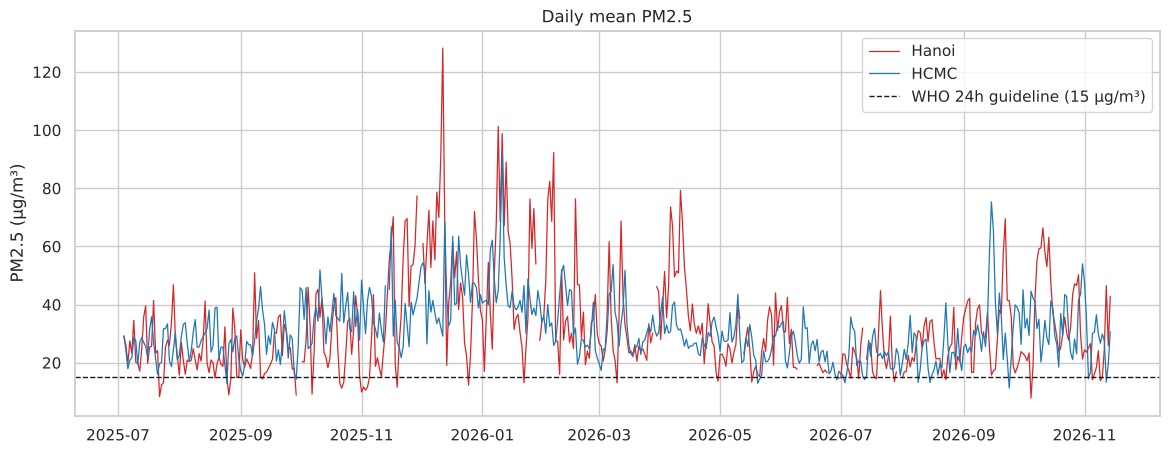

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
for city, df in raw.items():
    d = daily_means(df['pm25'])          # NaN (gap in the line) on days with < 18 measured hours
    ax.plot(d.index, d, label=city, color=CITY_COLORS[city], lw=0.9)
ax.axhline(WHO_24H, color='k', ls='--', lw=1, label='WHO 24h guideline (15 µg/m³)')
ax.set(title='Daily mean PM2.5', ylabel='PM2.5 (µg/m³)')
ax.legend()
plt.show()

**Figure 2 – Distribution of hourly PM2.5** and **Figure 3 – Monthly boxplots** (seasonality).

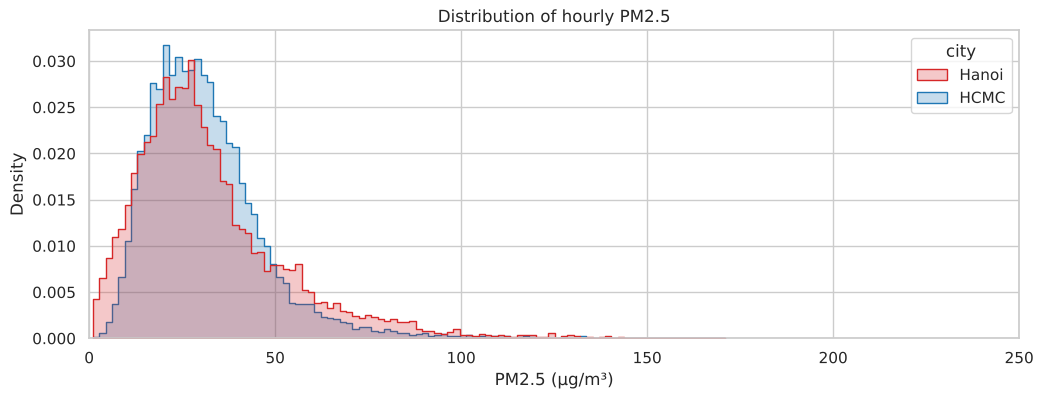

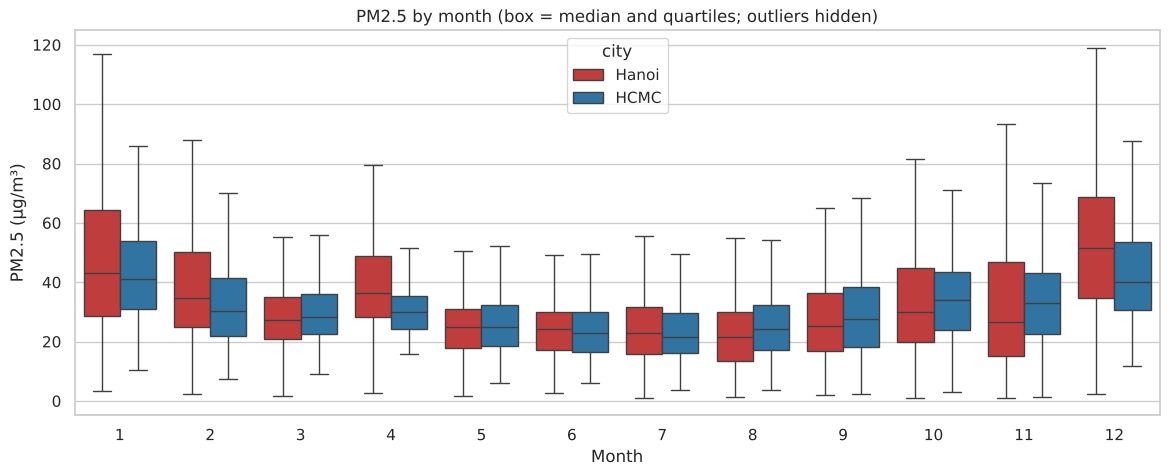

Hourly PM2.5 by calendar month (mean and median over all years, µg/m³):


mean       median      
city   HCMC Hanoi   HCMC Hanoi
month                         
1      45.0  48.7   41.2  43.0
2      33.5  41.0   30.4  34.8
3      31.0  30.4   28.4  27.2
4      30.3  40.3   29.8  36.4
5      26.1  26.4   25.0  24.8
6      24.1  24.6   23.0  24.1
7      23.4  24.2   21.5  23.0
8      25.2  22.8   24.1  21.5
9      30.1  27.9   27.7  25.4
10     35.2  32.9   34.0  30.0
11     34.3  33.2   33.0  26.8
12     44.4  54.1   40.1  51.7

In [5]:
plot_df = pd.concat([df[['pm25']].assign(city=city) for city, df in raw.items()])
plot_df['month'] = plot_df.index.month
plot_df['hour'] = plot_df.index.hour
plot_df = plot_df.reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=plot_df, x='pm25', hue='city', bins=100, element='step', stat='density',
             common_norm=False, palette=CITY_COLORS, ax=ax)
ax.set(title='Distribution of hourly PM2.5', xlabel='PM2.5 (µg/m³)', xlim=(0, 250))
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=plot_df, x='month', y='pm25', hue='city', palette=CITY_COLORS, showfliers=False, ax=ax)
ax.set(title='PM2.5 by month (box = median and quartiles; outliers hidden)', xlabel='Month', ylabel='PM2.5 (µg/m³)')
plt.show()

monthly = plot_df.groupby(['city', 'month'])['pm25'].agg(['mean', 'median']).round(1).unstack('city')
print('Hourly PM2.5 by calendar month (mean and median over all years, µg/m³):')
display(monthly)

**Figure 4 – Daily cycle:** mean PM2.5 by hour of day, split into the dry/cool half-year (Nov–Apr) and the wet/hot half-year (May–Oct).
Only **days with at least 18 measured hours** are used, so that every hour of the day is averaged over (almost) the same set of days.
With a plain mean by hour, an hour that is missing more often than others would be averaged over *different days*, and the shape of
the curve could reflect *which days have data* instead of the real daily cycle. With the chosen stations the coverage of every hour
of the day is close to the overall coverage (`worst_hour_cov` in Section 1.2), so this restriction changes little; it is kept as a safeguard.

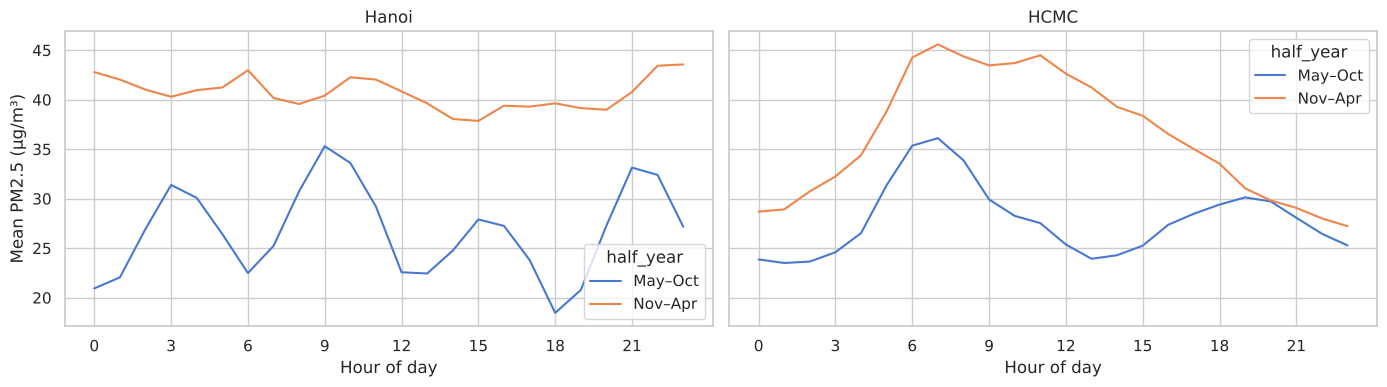

Hanoi May–Oct (285 complete days): highest mean at 9h (35.3 µg/m³), lowest at 18h (18.5 µg/m³)
Hanoi Nov–Apr (191 complete days): highest mean at 23h (43.6 µg/m³), lowest at 15h (37.9 µg/m³)
HCMC May–Oct (304 complete days): highest mean at 7h (36.1 µg/m³), lowest at 1h (23.5 µg/m³)
HCMC Nov–Apr (194 complete days): highest mean at 7h (45.6 µg/m³), lowest at 23h (27.2 µg/m³)


In [6]:
def complete_days_only(s, min_hours=MIN_HOURS_PER_DAY):
    """Keep only the hours of days that have at least `min_hours` measured hours."""
    measured_per_day = s.groupby(s.index.floor('D')).transform('count')
    return s[measured_per_day >= min_hours]


cycle_df = pd.concat([complete_days_only(df['pm25']).to_frame().assign(city=city) for city, df in raw.items()])
cycle_df['hour'] = cycle_df.index.hour
cycle_df['half_year'] = np.where(cycle_df.index.month.isin([11, 12, 1, 2, 3, 4]), 'Nov–Apr', 'May–Oct')

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, city in zip(axes, CITY_FILES):
    g = cycle_df[cycle_df.city == city]
    sns.lineplot(data=g, x='hour', y='pm25', hue='half_year', errorbar=None, ax=ax)
    ax.set(title=city, xlabel='Hour of day', ylabel='Mean PM2.5 (µg/m³)', xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

for city in CITY_FILES:
    for half, g in cycle_df[cycle_df.city == city].groupby('half_year'):
        by_hour = g.groupby('hour')['pm25'].mean()
        print(f'{city} {half} ({g.index.floor("D").nunique()} complete days): highest mean at {by_hour.idxmax()}h '
              f'({by_hour.max():.1f} µg/m³), lowest at {by_hour.idxmin()}h ({by_hour.min():.1f} µg/m³)')

**Figure 5 – Spearman correlation matrix** between PM2.5 and the weather variables, per city.

Hanoi – Spearman correlation of PM2.5 with: {'temperature_2m': -0.15, 'relative_humidity_2m': -0.14, 'precipitation': -0.27, 'wind_speed_10m': -0.2, 'surface_pressure': 0.26, 'cloud_cover': -0.29}


HCMC – Spearman correlation of PM2.5 with: {'temperature_2m': -0.03, 'relative_humidity_2m': -0.06, 'precipitation': -0.12, 'wind_speed_10m': -0.38, 'surface_pressure': 0.26, 'cloud_cover': -0.06}


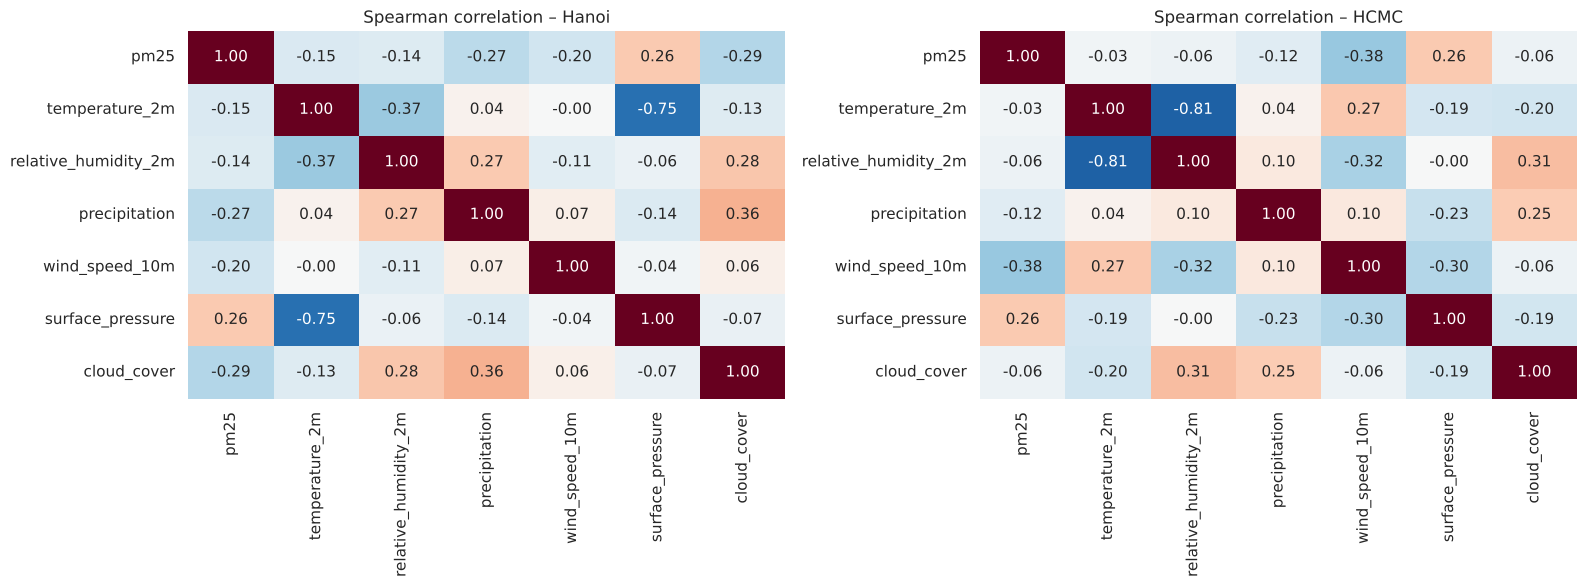

In [7]:
num_cols = ['pm25', 'temperature_2m', 'relative_humidity_2m', 'precipitation',
            'wind_speed_10m', 'surface_pressure', 'cloud_cover']
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (city, df) in zip(axes, raw.items()):
    sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'Spearman correlation – {city}')
    print(f'{city} – Spearman correlation of PM2.5 with:',
          df[num_cols].corr(method='spearman')['pm25'].drop('pm25').round(2).to_dict())
plt.tight_layout()
plt.show()

**Autocorrelation.** How much does the current value tell us about the value $k$ hours later? The lag-$k$ autocorrelation is the
Pearson correlation between the pairs $(x_t, x_{t-k})$ for all $t$ where both hours were measured
(`Series.autocorr(k)` in pandas). Lag 24h is the relevant one for a 24-hour-ahead forecast.

In [8]:
ACF_LAGS = [1, 2, 3, 6, 12, 24, 48]
acf_table = pd.DataFrame({city: [df['pm25'].autocorr(lag) for lag in ACF_LAGS] for city, df in raw.items()},
                         index=pd.Index(ACF_LAGS, name='lag (hours)'))
display(acf_table.round(2))

,Hanoi,HCMC
lag (hours),,
1,0.95,0.88
2,0.85,0.74
3,0.77,0.63
6,0.74,0.40
12,0.61,0.27
24,0.59,0.47
48,0.45,0.36


**EDA findings:**

_(Pending: written after the notebook is run on the current data.)_

## 2. DATA PREPARATION

The steps below are written as **reusable functions** and applied **identically** to each city,
but every city is processed **independently**.

### 2.1. Missing value statistics

,City,Missing hours,Missing rate,Gaps,Gaps ≤ 6h,Longest gap (hours)
0,Hanoi,432,3.6%,65,48,86
1,HCMC,75,0.6%,38,37,8


,Hanoi (% missing),HCMC (% missing)
city,0.00,0.00
temperature_2m,0.00,0.00
relative_humidity_2m,0.00,0.00
precipitation,0.00,0.00
wind_speed_10m,0.00,0.00
wind_direction_10m,0.00,0.00
surface_pressure,0.00,0.00
cloud_cover,0.00,0.00
pm25,3.61,0.63
pm25_source,0.00,0.00


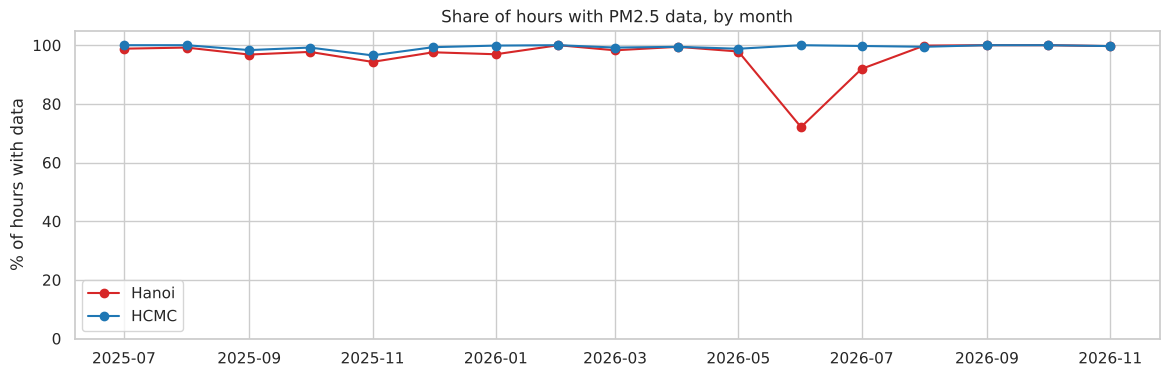

% of hours with missing PM2.5, by month:


datetime,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10,2026-11
Hanoi,1,1,3,2,6,2,3,0,2,1,2,28,8,0,0,0,0
HCMC,0,0,2,1,3,1,0,0,1,1,1,0,0,1,0,0,0


In [9]:
def gap_lengths(series):
    """Length (hours) of each run of consecutive missing values."""
    is_na = series.isna()
    groups = (is_na != is_na.shift()).cumsum()
    return is_na.groupby(groups).sum()[lambda s: s > 0]


def missing_report(raw_dict):
    rows = []
    for city, df in raw_dict.items():
        gaps = gap_lengths(df['pm25'])
        rows.append({'City': city, 'Missing hours': int(df['pm25'].isna().sum()),
                     'Missing rate': f"{df['pm25'].isna().mean():.1%}",
                     'Gaps': len(gaps), 'Gaps ≤ 6h': int((gaps <= 6).sum()),
                     'Longest gap (hours)': int(gaps.max()) if len(gaps) else 0})
    return pd.DataFrame(rows)


display(missing_report(raw))
display((pd.concat({city: df.isna().mean() for city, df in raw.items()}, axis=1) * 100)
        .round(2).rename(columns=lambda c: f'{c} (% missing)'))

fig, ax = plt.subplots(figsize=(14, 4))
for city, df in raw.items():
    avail = df['pm25'].notna().resample('MS').mean() * 100
    ax.plot(avail.index, avail, marker='o', label=city, color=CITY_COLORS[city])
ax.set(title='Share of hours with PM2.5 data, by month', ylabel='% of hours with data', ylim=(0, 105))
ax.legend()
plt.show()

missing_by_month = pd.DataFrame({city: df['pm25'].isna().resample('MS').mean() * 100 for city, df in raw.items()})
missing_by_month.index = missing_by_month.index.strftime('%Y-%m')
print('% of hours with missing PM2.5, by month:')
display(missing_by_month.round(0).astype(int).T)

### 2.2. Cleaning invalid values and handling missing data

- **Invalid values:** PM2.5 ≤ 0 or > 1000 µg/m³ are sensor errors → set to `NaN`
  (a reference monitor reporting exactly 0.0 is a dropout, not clean air).
- **"Stuck" sensor:** the same value repeated for ≥ 6 consecutive hours (with PM2.5 > 0) indicates a frozen device → set to `NaN`.
- **No look-ahead when filling.** Time interpolation (`interpolate(method='time')`) fills a gap using the value measured **after**
  the gap, which is not known yet at forecast time $t$. If the features were built from interpolated values, the model would
  see up to 6 hours of the future (Section 2.4 prints how many samples this would concern). We therefore keep two versions:
  - `pm25_raw` — the measured values only. **The target is always a measured value** (never filled), so the evaluation is done on real data.
  - `pm25` — `pm25_raw` **forward-filled for at most 6 hours** (`ffill(limit=6)`): "the last known value, if it is at most 6h old".
    This is causal (uses only data ≤ $t$) and is used to build the features.
- **Long gaps (> 6 hours):** not filled (that would fabricate data) → samples whose current value or target is missing are dropped;
  remaining missing features are handled by `SimpleImputer` (median, fitted on the training set) inside the pipeline.

Hanoi: 0 values ≤ 0 or > 1000, 0 stuck-sensor hours | missing PM2.5: 3.6% → 2.0% after cleaning + causal forward-fill (features only)
HCMC: 0 values ≤ 0 or > 1000, 0 stuck-sensor hours | missing PM2.5: 0.6% → 0.0% after cleaning + causal forward-fill (features only)


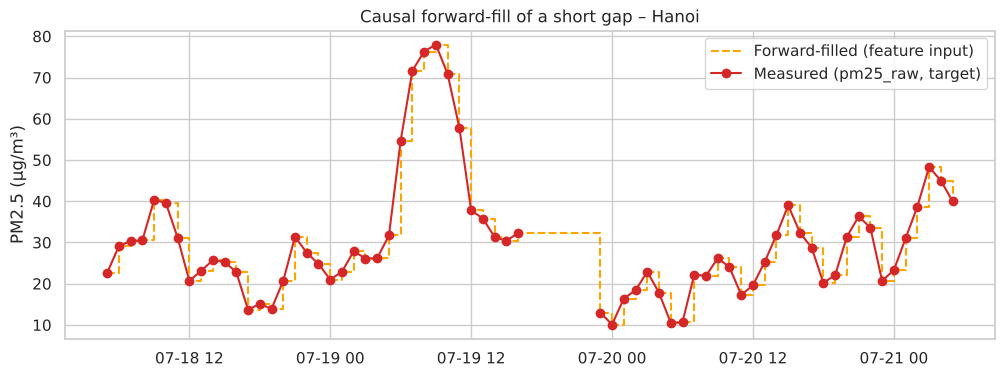

In [10]:
MAX_FILL_GAP = 6
STUCK_HOURS = 6


def clean_city(df):
    df = df.copy()
    pm = df['pm25']
    invalid = (pm <= 0) | (pm > 1000)
    run_id = (pm != pm.shift()).cumsum()
    run_len = pm.groupby(run_id).transform('size')
    stuck = (run_len >= STUCK_HOURS) & (pm > 0) & pm.notna()
    df.loc[invalid | stuck, 'pm25'] = np.nan
    df['pm25_raw'] = df['pm25']                                # measured values only (used for the target)
    df['pm25'] = df['pm25_raw'].ffill(limit=MAX_FILL_GAP)      # causal fill (used for the features)
    return df, int(invalid.sum()), int(stuck.sum())


clean = {}
for city, df in raw.items():
    clean[city], n_invalid, n_stuck = clean_city(df)
    before, after = df['pm25'].isna().mean(), clean[city]['pm25'].isna().mean()
    print(f'{city}: {n_invalid} values ≤ 0 or > 1000, {n_stuck} stuck-sensor hours | '
          f'missing PM2.5: {before:.1%} → {after:.1%} after cleaning + causal forward-fill (features only)')


def first_short_gap(series, min_len=3, max_len=MAX_FILL_GAP):
    is_na = series.isna()
    groups = (is_na != is_na.shift()).cumsum()
    sizes = is_na.groupby(groups).transform('sum')
    mask = is_na & (sizes >= min_len) & (sizes <= max_len)
    return series.index[mask][0] if mask.any() else None


for city in clean:
    gap_time = first_short_gap(clean[city]['pm25_raw'])
    if gap_time is not None:
        break
if gap_time is not None:
    window = clean[city].loc[gap_time - pd.Timedelta('36h'): gap_time + pd.Timedelta('36h')]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.step(window.index, window['pm25'], where='post', ls='--', color='orange', label='Forward-filled (feature input)')
    ax.plot(window.index, window['pm25_raw'], 'o-', color=CITY_COLORS[city], label='Measured (pm25_raw, target)')
    ax.set(title=f'Causal forward-fill of a short gap – {city}', ylabel='PM2.5 (µg/m³)')
    ax.legend()
    plt.show()

### 2.3. Outlier detection (IQR)
IQR rule: values outside $[Q1 - 3\cdot IQR,\ Q3 + 3\cdot IQR]$ are treated as extreme outliers.

Hanoi: upper bound = 106.7 µg/m³ | 99 outlier hours (0.86%) | days with most outliers: ['2025-12-12', '2026-02-06', '2026-01-11']
HCMC: upper bound = 93.5 µg/m³ | 78 outlier hours (0.66%) | days with most outliers: ['2026-01-11', '2025-11-16', '2025-12-13']


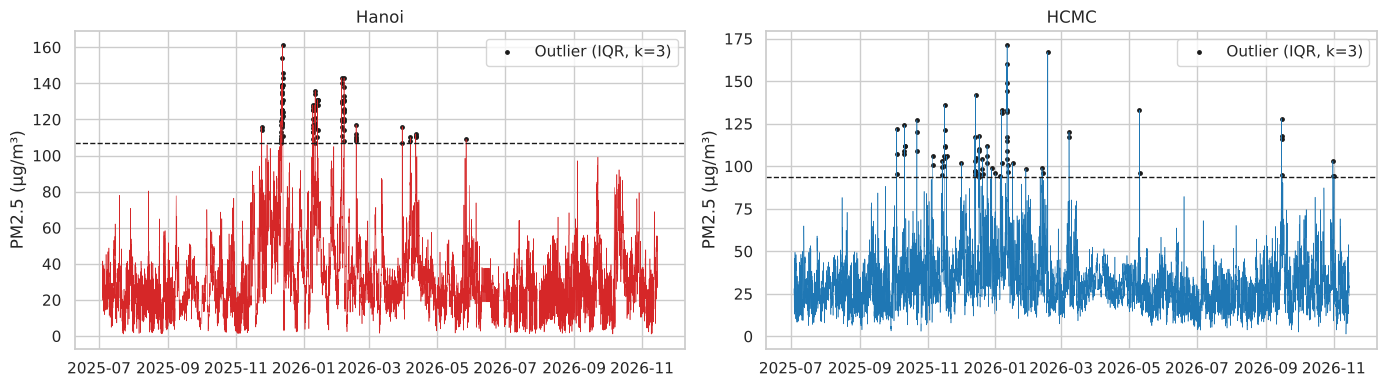

In [11]:
def iqr_bounds(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (city, df) in zip(axes, clean.items()):
    lo, hi = iqr_bounds(df['pm25_raw'])
    out = df.loc[df['pm25_raw'] > hi, 'pm25_raw']
    top_days = out.resample('D').count().nlargest(3).index.strftime('%Y-%m-%d').tolist()
    print(f'{city}: upper bound = {hi:.1f} µg/m³ | {len(out)} outlier hours '
          f'({len(out) / df.pm25_raw.notna().sum():.2%}) | days with most outliers: {top_days}')
    ax.plot(df.index, df['pm25_raw'], lw=0.4, color=CITY_COLORS[city])
    ax.scatter(out.index, out, s=6, color='k', label='Outlier (IQR, k=3)')
    ax.axhline(hi, color='k', ls='--', lw=1)
    ax.set(title=city, ylabel='PM2.5 (µg/m³)')
    ax.legend()
plt.tight_layout()
plt.show()

**Outlier decision:** PM2.5 peaks are **real events** (winter pollution episodes, straw burning, fireworks...),
so they are **not removed** from the target (removing them would make the evaluation look better than it is). Instead, the PM2.5
**features** (lags, rolling statistics) go through a custom `IQRClipper` transformer (bounds learned **on the training set only**)
to reduce the influence of extreme values on the linear model.

### 2.4. Feature engineering

Each sample at time $t$ has target `y = pm25_raw(t + 24h)` (a **measured** value). The features are built from the forward-filled
series and use only information **available at $t$** (no future leakage):

| Group | Features | Type |
|---|---|---|
| PM2.5 history | `pm25_lag_0, 1, 2, 3, 6, 12, 23` (value at $t-k$), `pm25_roll_mean_6/24`, `pm25_roll_std_24`, `pm25_diff_24` | numerical |
| Weather at $t$ | temperature, humidity, precipitation, wind speed, pressure, cloud cover, `rain_24h` (total rain over the last 24h) | numerical |
| Calendar of the forecast time | `hour_sin/cos` (cyclic hour encoding) | numerical |
| | `season` (climate season of each city), `day_of_week`, `wind_sector` (8 wind directions) | **categorical** |

> `pm25_lag_0` is the value at the **same hour on the previous day** relative to the forecast time, so the
> **Persistence** baseline (`ŷ(t+24) = pm25(t)`) is also the 24h *seasonal naive* baseline.

In [12]:
SEASONS = {
    'Hanoi': {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'},
    'HCMC': {m: ('Dry season' if m in (12, 1, 2, 3, 4) else 'Wet season') for m in range(1, 13)},
}
WIND_SECTORS = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
LAGS = [0, 1, 2, 3, 6, 12, 23]
WEATHER_RAW = ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m',
               'surface_pressure', 'cloud_cover']
WEATHER_FEATURES = WEATHER_RAW + ['rain_24h']
PM_FEATURES = [f'pm25_lag_{k}' for k in LAGS] + ['pm25_roll_mean_6', 'pm25_roll_mean_24',
                                                 'pm25_roll_std_24', 'pm25_diff_24']
CYCLIC_FEATURES = ['hour_sin', 'hour_cos']
CAT_FEATURES = ['season', 'day_of_week', 'wind_sector']
FEATURES = PM_FEATURES + WEATHER_FEATURES + CYCLIC_FEATURES + CAT_FEATURES
TARGET = 'target'


def build_features(df, city, horizon=HORIZON):
    """Build the features at each time t (using only data ≤ t)."""
    pm = df['pm25']
    X = pd.DataFrame(index=df.index)
    for k in LAGS:
        X[f'pm25_lag_{k}'] = pm.shift(k)
    X['pm25_roll_mean_6'] = pm.rolling(6, min_periods=3).mean()
    X['pm25_roll_mean_24'] = pm.rolling(24, min_periods=12).mean()
    X['pm25_roll_std_24'] = pm.rolling(24, min_periods=12).std()
    X['pm25_diff_24'] = pm - pm.shift(24)
    X[WEATHER_RAW] = df[WEATHER_RAW]
    X['rain_24h'] = df['precipitation'].rolling(24, min_periods=1).sum()

    target_time = df.index + pd.Timedelta(hours=horizon)
    X['hour_sin'] = np.sin(2 * np.pi * target_time.hour / 24)
    X['hour_cos'] = np.cos(2 * np.pi * target_time.hour / 24)
    X['season'] = pd.Series(target_time.month, index=df.index).map(SEASONS[city])
    X['day_of_week'] = target_time.day_name()
    sector_idx = ((df['wind_direction_10m'] + 22.5) % 360) // 45
    X['wind_sector'] = sector_idx.map(lambda i: WIND_SECTORS[int(i)] if pd.notna(i) else np.nan)
    return X


def make_dataset(df, city, horizon=HORIZON):
    """Add target = measured pm25_raw(t + horizon); keep only samples with a target and a current value."""
    X = build_features(df, city, horizon)
    X[TARGET] = df['pm25_raw'].shift(-horizon)
    return X.dropna(subset=[TARGET, 'pm25_lag_0'])


datasets = {city: make_dataset(df, city) for city, df in clean.items()}
for city, d in datasets.items():
    filled_now = clean[city]['pm25_raw'].reindex(d.index).isna().mean()   # current value comes from the forward-fill
    print(f'{city}: {len(d):,} samples | {len(FEATURES)} features '
          f'({len(FEATURES) - len(CAT_FEATURES)} numerical + {len(CAT_FEATURES)} categorical) | '
          f'{filled_now:.1%} of samples have a forward-filled current value '
          f'(with two-sided interpolation these would have used future measurements)')
datasets['Hanoi'].head()

Hanoi: 11,397 samples | 23 features (20 numerical + 3 categorical) | 1.0% of samples have a forward-filled current value (with two-sided interpolation these would have used future measurements)
HCMC: 11,875 samples | 23 features (20 numerical + 3 categorical) | 0.6% of samples have a forward-filled current value (with two-sided interpolation these would have used future measurements)


,pm25_lag_0,pm25_lag_1,pm25_lag_2,pm25_lag_3,pm25_lag_6,pm25_lag_12,pm25_lag_23,pm25_roll_mean_6,pm25_roll_mean_24,pm25_roll_std_24,...,wind_speed_10m,surface_pressure,cloud_cover,rain_24h,hour_sin,hour_cos,season,day_of_week,wind_sector,target
datetime,,,,,,,,,,,,,,,,,,,,,
2025-07-04 00:00:00,21.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.8,1006.0,100,0.0,0.000000,1.000000,Summer,Saturday,NW,18.0
2025-07-04 01:00:00,27.7,21.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.8,1005.5,100,0.0,0.258819,0.965926,Summer,Saturday,N,14.2
2025-07-04 02:00:00,27.3,27.7,21.6,NaN,NaN,NaN,NaN,25.533333,NaN,NaN,...,3.5,1004.9,100,0.0,0.500000,0.866025,Summer,Saturday,NW,14.2
2025-07-04 03:00:00,23.7,27.3,27.7,21.6,NaN,NaN,NaN,25.075000,NaN,NaN,...,4.6,1004.6,100,0.0,0.707107,0.707107,Summer,Saturday,NW,18.7
2025-07-04 04:00:00,25.5,23.7,27.3,27.7,NaN,NaN,NaN,25.160000,NaN,NaN,...,5.2,1004.6,100,0.0,0.866025,0.500000,Summer,Saturday,N,13.7


### 2.5. Chronological split: Development / Test, and walk-forward folds
A time series **must not be shuffled** (that would leak the future into the past), so every split follows **time order** and uses
the **same calendar dates for both cities**, so the two cities are compared over the same weather and season.

- **Test** = samples issued from **01/09/2026** to the end of the data (the last 2.5 months). It is used **once**, at the very end (Section 4).
- **Development** = all samples issued **before** 01/09/2026 − 24h. The extra `HORIZON` = 24 hours makes sure that the **target**
  ($t + 24h$) of every Development sample is measured before the first Test forecast is issued.

The data covers only one winter, and a single fixed Validation month (or 15% block) would fall in one season: a model would then be
chosen on, say, clean summer hours and judged on the polluted season. Model selection therefore uses **walk-forward validation**
(also called evaluation on a rolling forecasting origin, Tashman 2000; Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, §5.10):
for every month $m$ from **10/2025 to 08/2026** (11 folds), with $s_m$ the first hour of month $m$,

$$\text{Train}_m = \{t \in \text{Dev} : t < s_m - 24h\}, \qquad \text{Val}_m = \{t \in \text{Dev} : s_m \le t < s_{m+1}\}.$$

Each model is refitted on $\text{Train}_m$ (an **expanding** window: everything known before the month) and forecasts every sample
of $\text{Val}_m$. The 11 validation months do not overlap, so each Development hour from 10/2025 onwards is forecast **exactly once**,
by a model that never saw it, and the validation set covers the whole winter 2025–26. The first three months (07–09/2025) are only
used for training, so the first fold has a minimum amount of history.

Hanoi split: Development 9,598 (2025-07-04 → 2026-08-30 23:00) | Test 1,775 (2026-09-01 → 2026-11-13 22:00) samples | mean target: Development 32.3, Test 32.7 µg/m³
HCMC split: Development 10,076 (2025-07-04 → 2026-08-30 23:00) | Test 1,775 (2026-09-01 → 2026-11-13 22:00) samples | mean target: Development 31.0, Test 32.4 µg/m³


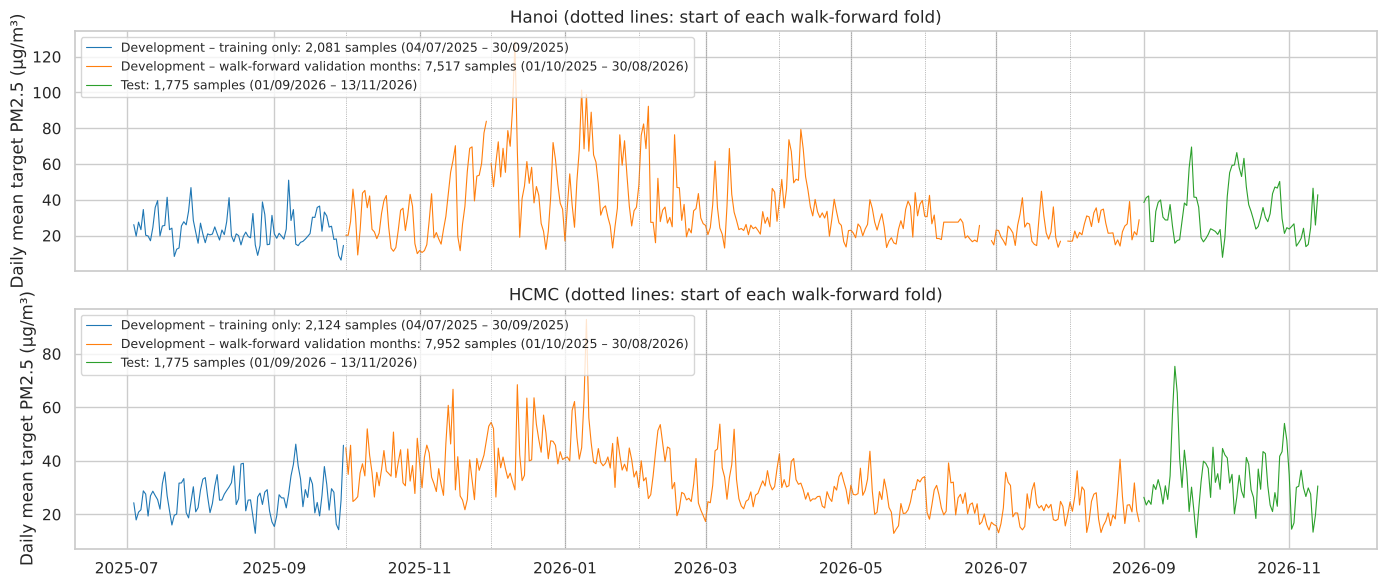

Walk-forward folds: number of samples in the training window and in the validation month


train       validation      
city     HCMC Hanoi       HCMC Hanoi
month                               
2025-10  2100  2075        738   723
2025-11  2838  2784        692   659
2025-12  3531  3463        740   726
2026-01  4270  4165        743   712
2026-02  5013  4877        672   672
2026-03  5685  5549        738   724
2026-04  6423  6273        716   716
2026-05  7139  6989        735   726
2026-06  7874  7715        720   487
2026-07  8594  8202        742   653
2026-08  9336  8870        716   719

In [13]:
TEST_START = pd.Timestamp('2026-09-01')
WALK_FORWARD_MONTHS = pd.period_range('2025-10', '2026-08', freq='M')


def dev_test_split(d, test_start=TEST_START, gap_hours=HORIZON):
    """Development = samples whose target is measured before test_start; Test = samples issued from test_start."""
    dev = d[d.index < test_start - pd.Timedelta(hours=gap_hours)]
    test = d[d.index >= test_start]
    return dev, test


def walk_forward_folds(dev, months=WALK_FORWARD_MONTHS, gap_hours=HORIZON):
    """For each month m: (m, train = samples whose target is known before m starts, val = samples issued in m)."""
    folds = []
    for m in months:
        start, end = m.start_time, (m + 1).start_time
        train = dev[dev.index < start - pd.Timedelta(hours=gap_hours)]
        val = dev[(dev.index >= start) & (dev.index < end)]
        folds.append((m, train, val))
    return folds


splits = {city: dev_test_split(d) for city, d in datasets.items()}

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, (city, (dev, te)) in zip(axes, splits.items()):
    pre_wf = dev[dev.index < WALK_FORWARD_MONTHS[0].start_time]
    wf = dev[dev.index >= WALK_FORWARD_MONTHS[0].start_time]
    for part, name, color in [(pre_wf, 'Development – training only', 'tab:blue'),
                              (wf, 'Development – walk-forward validation months', 'tab:orange'),
                              (te, 'Test', 'tab:green')]:
        daily = part[TARGET].resample('D').mean()
        ax.plot(daily.index, daily, color=color, lw=0.8,
                label=f'{name}: {len(part):,} samples ({part.index.min():%d/%m/%Y} – {part.index.max():%d/%m/%Y})')
    for m in WALK_FORWARD_MONTHS:
        ax.axvline(m.start_time, color='gray', lw=0.5, ls=':')
    ax.set(title=f'{city} (dotted lines: start of each walk-forward fold)', ylabel='Daily mean target PM2.5 (µg/m³)')
    ax.legend(loc='upper left', fontsize=9)
    print(f'{city} split: Development {len(dev):,} ({dev.index.min():%Y-%m-%d} → {dev.index.max():%Y-%m-%d %H:%M}) | '
          f'Test {len(te):,} ({te.index.min():%Y-%m-%d} → {te.index.max():%Y-%m-%d %H:%M}) samples | '
          f'mean target: Development {dev[TARGET].mean():.1f}, Test {te[TARGET].mean():.1f} µg/m³')
plt.tight_layout()
plt.show()

rows = []
for city, (dev, te) in splits.items():
    for m, tr, va in walk_forward_folds(dev):
        rows.append({'city': city, 'month': str(m), 'train': len(tr), 'validation': len(va)})
fold_sizes = pd.DataFrame(rows).pivot(index='month', columns='city', values=['train', 'validation'])
print('Walk-forward folds: number of samples in the training window and in the validation month')
display(fold_sizes)

_(Pending: written after the notebook is run on the current data.)_

### 2.6. Preprocessing pipeline (imputation, outlier clipping, encoding, scaling)

| Column group | Steps |
|---|---|
| PM2.5 lags/rolling | `SimpleImputer(median)` → `IQRClipper(k=3)` → `StandardScaler` |
| Weather + hour cycle | `SimpleImputer(median)` → `StandardScaler` |
| Categorical | `SimpleImputer(most_frequent)` → `OneHotEncoder` |

Everything lives inside a `ColumnTransformer` + `Pipeline`, so all parameters (medians, IQR bounds, mean/std, categories)
are **learned on the data the pipeline is fitted on** (the training window of each fold, or the whole Development set
for the final model), never on the data it is evaluated on → no data leakage.

After preprocessing: 39 columns (from 23 original columns, one-hot expands the categoricals)
Missing values left after the pipeline: 0


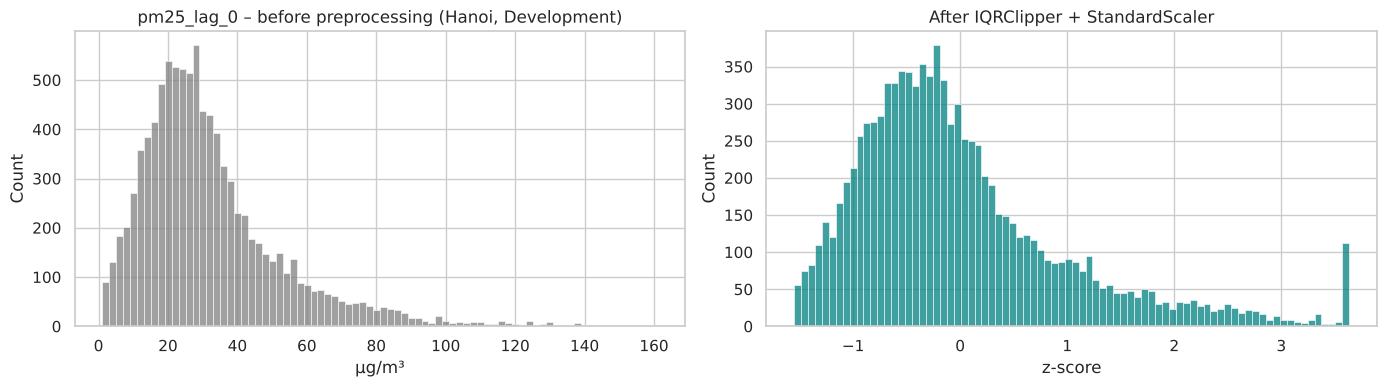

In [14]:
class IQRClipper(BaseEstimator, TransformerMixin):
    """Clip (winsorize) each column to [Q1 - k·IQR, Q3 + k·IQR], bounds learned on the fitted data."""

    def __init__(self, k=3.0):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
        self.lower_, self.upper_ = q1 - self.k * (q3 - q1), q3 + self.k * (q3 - q1)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_preprocessor():
    return ColumnTransformer([
        ('pm', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('clip', IQRClipper(k=3.0)),
                         ('scale', StandardScaler())]), PM_FEATURES),
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), WEATHER_FEATURES + CYCLIC_FEATURES),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CAT_FEATURES),
    ], sparse_threshold=0)


tr = splits['Hanoi'][0]   # Development set of Hanoi
pre = build_preprocessor().fit(tr[FEATURES])
Xt = pd.DataFrame(pre.transform(tr[FEATURES]), columns=pre.get_feature_names_out(), index=tr.index)
print(f'After preprocessing: {Xt.shape[1]} columns (from {len(FEATURES)} original columns, one-hot expands the categoricals)')
print('Missing values left after the pipeline:', int(Xt.isna().sum().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(tr['pm25_lag_0'], bins=80, ax=axes[0], color='gray')
axes[0].set(title='pm25_lag_0 – before preprocessing (Hanoi, Development)', xlabel='µg/m³')
sns.histplot(Xt['pm__pm25_lag_0'], bins=80, ax=axes[1], color='teal')
axes[1].set(title='After IQRClipper + StandardScaler', xlabel='z-score')
plt.tight_layout()
plt.show()

## 3. ANALYSIS AND MODELING

### 3.1. Models compared
| Model | Role | Why |
|---|---|---|
| **Persistence (baseline)** | `ŷ(t+24) = pm25(t)` | Standard time series baseline (= 24h seasonal naive) |
| **Mean 24h (baseline)** | `ŷ(t+24) = mean(pm25[t-23 … t])` | Smooths out the noise of a single hour |
| **Naive blend (baseline)** | `ŷ = w·pm25(t) + (1−w)·mean_24h(t)` | The **strongest naive baseline**: `w` is learned on the training data (grid 0, 0.05, …, 1, minimizing MAE). An ML model is only really useful if it beats **this** one, not just Persistence |
| **Ridge Regression** | Regularized linear model | Simple and interpretable; tests how linear the relationship is |
| **Random Forest** | Tree ensemble (bagging) | Captures non-linear effects and weather × hour interactions |
| **HistGradientBoosting** | Tree ensemble (boosting) | Strong and fast on large tabular data |

**Hyperparameter tuning:** `GridSearchCV` with `TimeSeriesSplit(n_splits=3, gap=24)` on the **Development** set, scored by `MAE`.
The validation fold always comes **after** the training fold, and the `gap` drops 24 samples between them so that the targets
(24h ahead) of the last training samples do not fall inside the validation fold. All three ML models are tuned
(Random Forest with a small grid to keep the run time reasonable on Colab). The printout flags any selected value that lies at
the smallest or largest end of its grid, because the best value could then lie outside the grid, and shows the best and worst
cross-validated MAE over the grid, i.e. how much the choice of hyperparameters matters at all for each model. (For Ridge, the smallest `alpha` is not a concern: as `alpha` → 0 Ridge tends to ordinary least squares.) The hyperparameters are then **fixed** for every
walk-forward fold and for the final model.

**Model selection:** walk-forward validation (Section 2.5). Every model, baselines included, is refitted on each training window
$\text{Train}_m$ (so the blend weight $w$ is also re-learned in every fold) and forecasts month $m$. The scores are computed on the
**pooled** forecasts of the 11 months, e.g. $\mathrm{MAE} = \sum_m \sum_{i \in \text{Val}_m} |y_i - \hat y_i| \, / \, \sum_m |\text{Val}_m|$,
and the ML model with the lowest pooled MAE is the **best model** of the city.

*Stated limitation:* the hyperparameters were tuned on the whole Development set, which contains the walk-forward months, so the
walk-forward errors of the three ML models are **slightly optimistic** (the baselines have no hyperparameters). Re-tuning inside each
of the 11 folds (nested tuning) would remove this bias but multiplies the run time by about 11. The Test set (Section 4) is not
affected: it was never used for tuning or selection.

The `CityForecaster` class wraps the whole workflow for **one** city so that it can be repeated for both.

In [15]:
class PersistenceBaseline(BaseEstimator, RegressorMixin):
    """Forecast PM2.5 HORIZON hours ahead with the current value."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.asarray(X['pm25_lag_0'], dtype=float)


class MeanBaseline(BaseEstimator, RegressorMixin):
    """Forecast PM2.5 HORIZON hours ahead with the mean of the last 24 hours."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return np.asarray(X['pm25_roll_mean_24'].fillna(X['pm25_lag_0']), dtype=float)


class NaiveBlend(BaseEstimator, RegressorMixin):
    """w·(current value) + (1 − w)·(24h mean); w is chosen on the fitted data to minimize MAE."""

    def __init__(self, weights=tuple(np.round(np.linspace(0, 1, 21), 2))):
        self.weights = weights

    @staticmethod
    def _parts(X):
        now = np.asarray(X['pm25_lag_0'], dtype=float)
        return now, np.asarray(X['pm25_roll_mean_24'].fillna(X['pm25_lag_0']), dtype=float)

    def fit(self, X, y):
        now, mean24 = self._parts(X)
        maes = [np.mean(np.abs(np.asarray(y) - (w * now + (1 - w) * mean24))) for w in self.weights]
        self.w_ = float(self.weights[int(np.argmin(maes))])
        return self

    def predict(self, X):
        now, mean24 = self._parts(X)
        return self.w_ * now + (1 - self.w_) * mean24


BASELINES = ['Persistence (baseline)', 'Mean 24h (baseline)', 'Naive blend (baseline)']


def regression_metrics(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}


def make_models():
    return {
        'Persistence (baseline)': PersistenceBaseline(),
        'Mean 24h (baseline)': MeanBaseline(),
        'Naive blend (baseline)': NaiveBlend(),
        'Ridge': Pipeline([('pre', build_preprocessor()), ('model', Ridge())]),
        'RandomForest': Pipeline([('pre', build_preprocessor()), ('model', RandomForestRegressor(
            n_estimators=200, max_depth=12, min_samples_leaf=10, max_features=0.5,
            n_jobs=-1, random_state=RANDOM_STATE))]),
        # early_stopping=False: the default 'auto' switches early stopping on above 10,000 samples and then holds out a
        # *random* 10% of the rows (not a time-ordered split), so the model would behave differently in the CV folds
        # (< 10,000 rows) and in the final fit; with False the number of trees is always exactly max_iter.
        'HistGradientBoosting': Pipeline([('pre', build_preprocessor()),
                                          ('model', HistGradientBoostingRegressor(early_stopping=False,
                                                                                  random_state=RANDOM_STATE))]),
    }


PARAM_GRIDS = {
    'Ridge': {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    'RandomForest': {'model__max_depth': [4, 6, 8, 12],
                     'model__min_samples_leaf': [5, 10, 30, 100]},
    'HistGradientBoosting': {'model__learning_rate': [0.01, 0.03, 0.1],
                             'model__max_iter': [100, 200, 400],
                             'model__max_leaf_nodes': [4, 7, 15],
                             'model__l2_regularization': [1.0, 10.0, 100.0]},
}


class CityForecaster:
    def __init__(self, city, dev, test):
        self.city, self.dev, self.test = city, dev, test
        self.models = make_models()
        self.best_params, self.cv_mae_range = {}, {}

    def tune(self):
        for name, grid in PARAM_GRIDS.items():
            search = GridSearchCV(self.models[name], grid, cv=TimeSeriesSplit(n_splits=3, gap=HORIZON),
                                  scoring='neg_mean_absolute_error', n_jobs=-1)
            search.fit(self.dev[FEATURES], self.dev[TARGET])
            self.models[name] = search.best_estimator_
            self.best_params[name] = search.best_params_
            self.cv_mae_range[name] = (-search.cv_results_['mean_test_score'].max(),
                                       -search.cv_results_['mean_test_score'].min())
        return self

    def walk_forward(self):
        """Refit every model on each expanding training window and forecast the next month (Section 2.5)."""
        parts = []
        for month, train, val in walk_forward_folds(self.dev):
            p = pd.DataFrame({'actual': val[TARGET], 'fold': str(month)})
            for name, model in self.models.items():
                m = clone(model)                      # same hyperparameters, fitted from scratch
                m.fit(train[FEATURES], train[TARGET])
                p[name] = m.predict(val[FEATURES])
            parts.append(p)
        self.wf_predictions = pd.concat(parts)
        return pd.DataFrame([{'city': self.city, 'model': name,
                              **regression_metrics(self.wf_predictions['actual'], self.wf_predictions[name])}
                             for name in self.models])

    def evaluate_on_test(self):
        """Refit on the whole Development set, then evaluate once on Test."""
        rows, self.test_predictions = [], pd.DataFrame({'actual': self.test[TARGET]})
        for name, m in self.models.items():
            m.fit(self.dev[FEATURES], self.dev[TARGET])
            pred = m.predict(self.test[FEATURES])
            self.test_predictions[name] = pred
            rows.append({'city': self.city, 'model': name, **regression_metrics(self.test[TARGET], pred)})
        return pd.DataFrame(rows)


forecasters = {city: CityForecaster(city, *parts).tune() for city, parts in splits.items()}
for city, f in forecasters.items():
    print(f'{city} – best hyperparameters:')
    for name, params in f.best_params.items():
        # a value at the smallest or largest end of its grid means the optimum may lie outside the grid
        at_edge = [k.replace('model__', '') for k, v in params.items()
                   if len(PARAM_GRIDS[name][k]) > 1 and v in (min(PARAM_GRIDS[name][k]), max(PARAM_GRIDS[name][k]))]
        best_cv, worst_cv = f.cv_mae_range[name]
        print(f'   {name}: {params} | at the edge of the grid: {at_edge if at_edge else "none"} | '
              f'CV MAE best {best_cv:.2f}, worst {worst_cv:.2f} over the grid')
    blend = clone(f.models['Naive blend (baseline)']).fit(f.dev[FEATURES], f.dev[TARGET])
    print(f'   Naive blend: w = {blend.w_:.2f} (weight of the current value, learned on the whole Development set)')

Hanoi – best hyperparameters:
   Ridge: {'model__alpha': 0.01} | at the edge of the grid: ['alpha'] | CV MAE best 12.87, worst 13.76 over the grid
   RandomForest: {'model__max_depth': 8, 'model__min_samples_leaf': 5} | at the edge of the grid: ['min_samples_leaf'] | CV MAE best 13.56, worst 14.18 over the grid
   HistGradientBoosting: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_iter': 400, 'model__max_leaf_nodes': 4} | at the edge of the grid: ['l2_regularization', 'max_iter', 'max_leaf_nodes'] | CV MAE best 13.24, worst 15.46 over the grid
   Naive blend: w = 0.65 (weight of the current value, learned on the whole Development set)
HCMC – best hyperparameters:
   Ridge: {'model__alpha': 10} | at the edge of the grid: none | CV MAE best 10.04, worst 10.21 over the grid
   RandomForest: {'model__max_depth': 4, 'model__min_samples_leaf': 10} | at the edge of the grid: ['max_depth'] | CV MAE best 10.32, worst 10.79 over the grid
   HistGradientBoosting: {'m

### 3.2. Walk-forward validation (model selection)
Pooled scores over the 11 monthly folds (10/2025 – 08/2026), then the MAE of each model in each month.

In [16]:
wf_results = pd.concat([f.walk_forward() for f in forecasters.values()], ignore_index=True)
wf_table = wf_results.pivot(index='model', columns='city', values=['MAE', 'RMSE', 'R2'])
display(wf_table.reindex(columns=list(CITY_FILES), level=1).reindex(list(make_models())).round(3))

ml_wf = wf_results[~wf_results.model.isin(BASELINES)]
best_model = ml_wf.loc[ml_wf.groupby('city')['MAE'].idxmin()].set_index('city')['model']
print('Best model (lowest pooled walk-forward MAE among the ML models):', best_model.to_dict())

for city, f in forecasters.items():
    w_per_fold = {}
    for month, train, val in walk_forward_folds(f.dev):
        w_per_fold[str(month)] = clone(f.models['Naive blend (baseline)']).fit(train[FEATURES], train[TARGET]).w_
    print(f'{city} – Naive blend weight w learned in each fold:', w_per_fold)

MAE            RMSE             R2       
city                     Hanoi    HCMC   Hanoi    HCMC  Hanoi   HCMC
model                                                               
Persistence (baseline)  13.788  10.895  19.983  16.533  0.183 -0.030
Mean 24h (baseline)     14.836  10.850  20.650  15.194  0.127  0.130
Naive blend (baseline)  13.358   9.921  19.186  14.496  0.247  0.208
Ridge                   12.521   9.630  17.365  13.639  0.383  0.299
RandomForest            12.453   9.751  17.770  13.822  0.354  0.280
HistGradientBoosting    12.646   9.593  18.048  13.588  0.334  0.304

Best model (lowest pooled walk-forward MAE among the ML models): {'HCMC': 'HistGradientBoosting', 'Hanoi': 'RandomForest'}
Hanoi – Naive blend weight w learned in each fold: {'2025-10': 0.65, '2025-11': 0.7, '2025-12': 0.75, '2026-01': 0.75, '2026-02': 0.75, '2026-03': 0.65, '2026-04': 0.65, '2026-05': 0.65, '2026-06': 0.65, '2026-07': 0.65, '2026-08': 0.65}
HCMC – Naive blend weight w learned in each fold: {'2025-10': 0.55, '2025-11': 0.45, '2025-12': 0.45, '2026-01': 0.45, '2026-02': 0.5, '2026-03': 0.5, '2026-04': 0.5, '2026-05': 0.5, '2026-06': 0.5, '2026-07': 0.5, '2026-08': 0.5}


**Figure – Walk-forward MAE by month** for every model. Each point is the MAE of the forecasts issued in that month by a model trained
only on data known before the month started. The bars show the mean measured PM2.5 (target) of the month, for context.

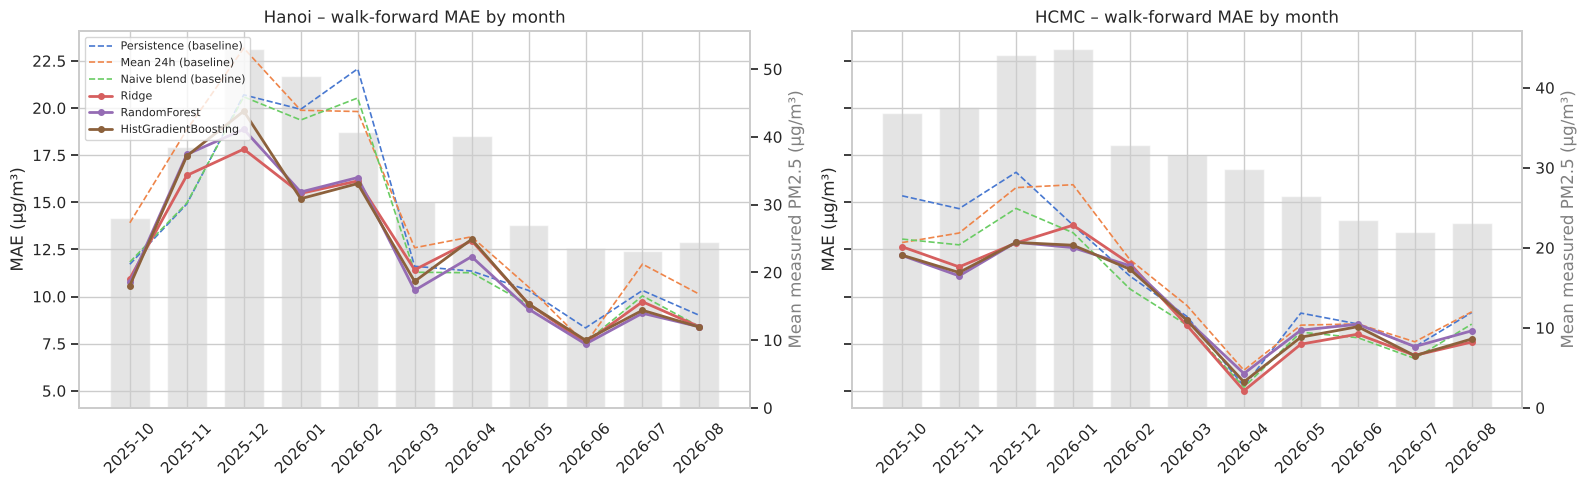

Hanoi – walk-forward MAE by month (µg/m³):


fold,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
Persistence (baseline),11.71,14.91,20.70,19.93,22.08,11.60,11.35,10.32,8.34,10.32,9.00
Mean 24h (baseline),13.91,18.85,23.18,19.88,19.82,12.59,13.17,10.51,7.50,11.72,10.12
Naive blend (baseline),11.83,14.96,20.59,19.36,20.53,11.29,11.26,9.56,7.57,10.03,8.41
Ridge,10.95,16.42,17.82,15.47,16.13,11.42,12.96,9.61,7.54,9.72,8.40
RandomForest,10.74,17.54,18.87,15.54,16.31,10.33,12.12,9.34,7.48,9.11,8.39
HistGradientBoosting,10.58,17.45,19.83,15.19,15.99,10.80,13.03,9.61,7.68,9.27,8.38


HCMC – walk-forward MAE by month (µg/m³):


fold,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
Persistence (baseline),15.34,14.66,16.59,13.79,11.08,8.94,5.24,9.12,8.54,7.33,9.15
Mean 24h (baseline),12.86,13.37,15.78,15.93,11.95,9.52,6.09,8.48,8.55,7.60,9.19
Naive blend (baseline),13.05,12.74,14.67,13.38,10.40,8.48,5.19,8.11,7.82,6.71,8.53
Ridge,12.64,11.57,12.84,13.78,11.74,8.46,5.00,7.47,8.00,6.87,7.58
RandomForest,12.18,11.09,12.88,12.59,11.63,8.76,5.91,8.21,8.53,7.35,8.18
HistGradientBoosting,12.19,11.27,12.87,12.72,11.45,8.74,5.47,7.84,8.40,6.86,7.75


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
monthly_mae = {}
for ax, (city, f) in zip(axes, forecasters.items()):
    p = f.wf_predictions
    abs_err = p[list(f.models)].sub(p['actual'], axis=0).abs()
    monthly_mae[city] = abs_err.groupby(p['fold']).mean()
    level = p.groupby('fold')['actual'].mean()
    ax2 = ax.twinx()
    ax2.bar(range(len(level)), level, color='lightgray', alpha=0.6, width=0.7)
    ax2.set_ylabel('Mean measured PM2.5 (µg/m³)', color='gray')
    ax2.grid(False)
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    for name in f.models:
        style = dict(ls='--', lw=1.2) if name in BASELINES else dict(lw=2, marker='o', ms=4)
        ax.plot(range(len(level)), monthly_mae[city][name].reindex(level.index), label=name, **style)
    ax.set_xticks(range(len(level)), level.index, rotation=45)
    ax.set(title=f'{city} – walk-forward MAE by month', ylabel='MAE (µg/m³)')
axes[0].legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

for city in CITY_FILES:
    print(f'{city} – walk-forward MAE by month (µg/m³):')
    display(monthly_mae[city].T.reindex(list(make_models())).round(2))

_(Pending: written after the notebook is run on the current data.)_

## 4. SUMMARY AND EXTENSIONS

### 4.1. Results on the independent Test set
Each model is refitted on the whole Development set (with its hyperparameters fixed) and evaluated **once** on Test
(01/09/2026 to the end of the data). The **best model of each city was chosen by walk-forward validation** (Section 3.2), not on Test,
so the Test set is used only for reporting and its scores are not biased by model selection.
*Note:* the Test period is the **start** of the polluted season (September–November), not its peak (December–February);
the winter is covered by the walk-forward months.

In [18]:
test_results = pd.concat([f.evaluate_on_test() for f in forecasters.values()], ignore_index=True)
for ref, col in [('Persistence (baseline)', 'MAE vs Persistence'), ('Naive blend (baseline)', 'MAE vs Naive blend')]:
    ref_mae = test_results[test_results.model == ref].set_index('city')['MAE']
    test_results[col] = test_results.apply(lambda r: 1 - r['MAE'] / ref_mae[r['city']], axis=1)
display(test_results.set_index(['city', 'model']).style.format(
    {'MAE': '{:.2f}', 'RMSE': '{:.2f}', 'R2': '{:.3f}', 'MAE vs Persistence': '{:+.1%}', 'MAE vs Naive blend': '{:+.1%}'}))
print('Test:', {c: f.test.index.min().strftime('%Y-%m-%d') + ' → ' + f.test.index.max().strftime('%Y-%m-%d')
                for c, f in forecasters.items()})
print('Best model (chosen by walk-forward validation, Section 3.2):', best_model.to_dict())

Test: {'Hanoi': '2026-09-01 → 2026-11-13', 'HCMC': '2026-09-01 → 2026-11-13'}
Best model (chosen by walk-forward validation, Section 3.2): {'HCMC': 'HistGradientBoosting', 'Hanoi': 'RandomForest'}


### 4.2. Question: *How much better than the baseline is machine learning in each city?*
**Figure 6 – Test MAE** of each model, per city. Bar labels: % MAE reduction vs. the **Naive blend** baseline
(the strongest naive forecast), so a negative label means "worse than the naive blend".

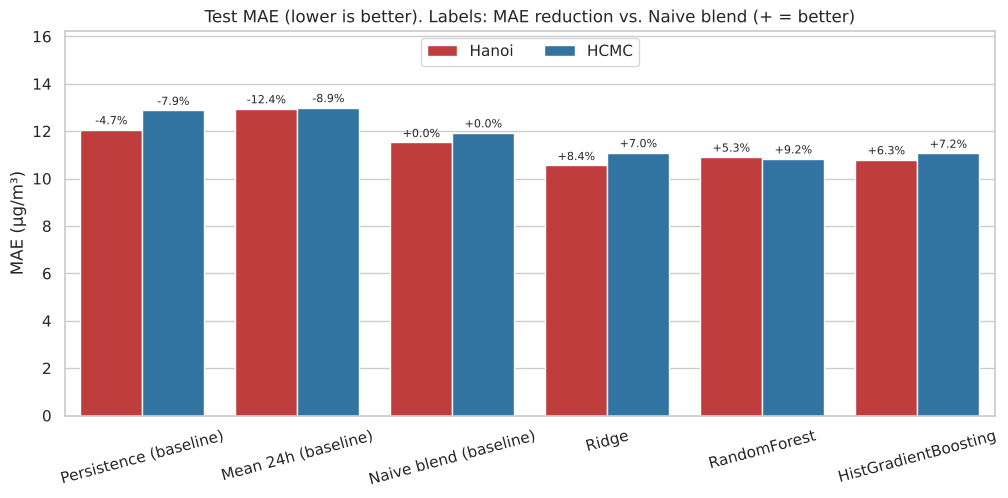

In [19]:
MODEL_ORDER = list(make_models())
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=test_results, x='model', y='MAE', hue='city', order=MODEL_ORDER,
            hue_order=list(CITY_FILES), palette=CITY_COLORS, ax=ax)
for container, city in zip(ax.containers, CITY_FILES):
    sub = test_results[test_results.city == city].set_index('model')
    ax.bar_label(container, labels=[f"{sub.loc[m, 'MAE vs Naive blend']:+.1%}" for m in MODEL_ORDER],
                 fontsize=8, padding=2)
ax.set(title='Test MAE (lower is better). Labels: MAE reduction vs. Naive blend (+ = better)', xlabel='', ylabel='MAE (µg/m³)')
ax.tick_params(axis='x', labelrotation=15)
ax.set_ylim(0, test_results['MAE'].max() * 1.25)
ax.legend(title='', loc='upper center', ncol=2)
plt.show()

_(Pending: written after the notebook is run on the current data.)_

### 4.3. Are the differences real? Block-bootstrap confidence intervals
Thousands of hourly forecasts sound like a lot, but forecast errors are **strongly autocorrelated** (an error at 10h is very
likely to be followed by a similar error at 11h), so the number of *independent* observations is much smaller, and an
ordinary i.i.d. bootstrap over hours would give intervals that are far too narrow.

**Method (non-overlapping block bootstrap, Carlstein 1986; the block idea for dependent data is also in Künsch 1989).**
For a comparison of model $A$ (the best model) with model $B$ on one evaluation set (the pooled walk-forward forecasts, or Test):
1. Split the samples into $k$ consecutive **3-day calendar blocks** of forecast time $t+24h$. Blocks do not overlap; because of
   missing hours they do not all contain the same number of samples. Let $S_j^A = \sum_{i \in j} |y_i - \hat y_i^A|$ be the sum of
   absolute errors of $A$ in block $j$ (same for $B$, on the **same** hours — the comparison is *paired*).
2. Draw $k$ blocks **with replacement**, i.e. counts $(c_1, \dots, c_k) \sim \mathrm{Multinomial}(k; 1/k, \dots, 1/k)$, and compute
   $g^* = 1 - \sum_j c_j S_j^A \, / \, \sum_j c_j S_j^B$ (the hour counts cancel because both models are scored on the same hours).
3. Repeat 2,000 times; the 2.5th and 97.5th percentiles of $g^*$ form the 95% **percentile** confidence interval of the gain
   $g = 1 - \mathrm{MAE}_A / \mathrm{MAE}_B$.

An interval that excludes 0 corresponds (approximately) to rejecting "no difference" in a two-sided test at the 5% level.
**Choice of block length:** blocks must be long enough that the error differences of different blocks are close to independent.
The cell below prints, on the walk-forward forecasts, the autocorrelation of the *daily mean* error difference between the best model and the
Naive blend at lags of 1, 2 and 3 days; the 3-day block length is checked against it, and 1-day and 7-day blocks are reported as a sensitivity check.

**Limitations of the method, stated explicitly:** (1) the percentile interval is an approximation, especially on Test, which has few blocks
(the number of blocks is the `blocks` column of the table); (2) we report 16 intervals without a multiple-comparison correction, so they are
**descriptive** — the conclusions are based on the four comparisons fixed in advance: best model vs Naive blend, on walk-forward and on Test,
for each city; (3) blocks assume the error process is roughly stationary within the evaluation period, which is only approximately true over
11 months with a winter in the middle; (4) on walk-forward, the best model was selected on these same forecasts and its hyperparameters
were tuned on the Development set, so its walk-forward gain is slightly optimistic — the Test interval is the unbiased one.

In [20]:
BLOCK_DAYS = 3
N_BOOT = 2000

# Block-length check on the walk-forward forecasts: autocorrelation of the daily mean |error| difference (best model − Naive blend)
for city, f in forecasters.items():
    p = f.wf_predictions
    diff = (p[best_model[city]] - p['actual']).abs() - (p['Naive blend (baseline)'] - p['actual']).abs()
    daily_diff = diff.groupby((diff.index + pd.Timedelta(hours=HORIZON)).floor('D')).mean().asfreq('D')
    print(f'{city} (walk-forward): autocorrelation of the daily error difference at lag 1/2/3 days = '
          + ' / '.join(f'{daily_diff.autocorr(k):.2f}' for k in (1, 2, 3)))


def block_bootstrap_gain(p, model_a, model_b, block_days=BLOCK_DAYS, n_boot=N_BOOT, seed=RANDOM_STATE):
    """Paired block bootstrap of the MAE gain of model_a over model_b, i.e. 1 - MAE_a / MAE_b.

    p: DataFrame indexed by issue time t with an 'actual' column and one column per model.
    Samples are grouped into consecutive calendar blocks of `block_days` days (forecast time t + HORIZON);
    whole blocks are resampled with replacement, keeping the autocorrelation of the errors inside each block.
    """
    t = p.index + pd.Timedelta(hours=HORIZON)
    codes = pd.factorize(np.asarray((t - t.min()) // pd.Timedelta(days=block_days)))[0]
    abs_err_a = np.bincount(codes, weights=np.abs(p[model_a] - p['actual']))   # error sum per block
    abs_err_b = np.bincount(codes, weights=np.abs(p[model_b] - p['actual']))
    k = len(abs_err_a)
    counts = np.random.default_rng(seed).multinomial(k, np.full(k, 1 / k), size=n_boot)  # how often each block is drawn
    gains = 1 - (counts @ abs_err_a) / (counts @ abs_err_b)
    low, high = np.percentile(gains, [2.5, 97.5])
    return {'gain': 1 - abs_err_a.sum() / abs_err_b.sum(), 'ci_low': low, 'ci_high': high, 'blocks': k}


def competitors(city):
    return ['Persistence (baseline)', 'Naive blend (baseline)'] + [
        m for m in ['Ridge', 'RandomForest', 'HistGradientBoosting'] if m != best_model[city]]


rows = []
for city, f in forecasters.items():
    for set_name, preds in [('Walk-forward', f.wf_predictions), ('Test', f.test_predictions)]:
        for other in competitors(city):
            rows.append({'city': city, 'set': set_name, 'model': best_model[city], 'vs': other,
                         **block_bootstrap_gain(preds, best_model[city], other)})
boot = pd.DataFrame(rows)
boot['CI excludes 0'] = (boot['ci_low'] > 0) | (boot['ci_high'] < 0)
display(boot.style.format({'gain': '{:+.1%}', 'ci_low': '{:+.1%}', 'ci_high': '{:+.1%}'}))
for r in boot.itertuples():
    print(f'BOOT | {r.city} | {r.set} | {r.model} vs {r.vs} | gain {r.gain:+.1%} [{r.ci_low:+.1%}, {r.ci_high:+.1%}]')

print('\nSensitivity to the block length (best model vs Naive blend):')
for city, f in forecasters.items():
    for set_name, preds in [('Walk-forward', f.wf_predictions), ('Test', f.test_predictions)]:
        cis = {L: block_bootstrap_gain(preds, best_model[city], 'Naive blend (baseline)', block_days=L)
               for L in (1, 3, 7)}
        print(f'{city} {set_name}: ' + ' | '.join(f"{L}-day blocks ({c['blocks']}): [{c['ci_low']:+.1%}, {c['ci_high']:+.1%}]"
                                                  for L, c in cis.items()))

Hanoi (walk-forward): autocorrelation of the daily error difference at lag 1/2/3 days = 0.15 / -0.06 / 0.02
HCMC (walk-forward): autocorrelation of the daily error difference at lag 1/2/3 days = 0.16 / 0.20 / 0.10


,city,set,model,vs,gain,ci_low,ci_high,blocks,CI excludes 0
0,Hanoi,Walk-forward,RandomForest,Persistence (baseline),+9.7%,+2.0%,+16.5%,111,True
1,Hanoi,Walk-forward,RandomForest,Naive blend (baseline),+6.8%,-0.9%,+13.7%,111,False
2,Hanoi,Walk-forward,RandomForest,Ridge,+0.5%,-2.5%,+3.8%,111,False
3,Hanoi,Walk-forward,RandomForest,HistGradientBoosting,+1.5%,-0.4%,+3.3%,111,False
4,Hanoi,Test,RandomForest,Persistence (baseline),+9.6%,+1.5%,+17.3%,25,True
5,Hanoi,Test,RandomForest,Naive blend (baseline),+5.3%,-3.4%,+13.3%,25,False
6,Hanoi,Test,RandomForest,Ridge,-3.4%,-9.3%,+1.6%,25,False
7,Hanoi,Test,RandomForest,HistGradientBoosting,-1.0%,-5.6%,+2.3%,25,False
8,HCMC,Walk-forward,HistGradientBoosting,Persistence (baseline),+12.0%,+7.4%,+15.8%,112,True
9,HCMC,Walk-forward,HistGradientBoosting,Naive blend (baseline),+3.3%,-1.4%,+7.6%,112,False


BOOT | Hanoi | Walk-forward | RandomForest vs Persistence (baseline) | gain +9.7% [+2.0%, +16.5%]
BOOT | Hanoi | Walk-forward | RandomForest vs Naive blend (baseline) | gain +6.8% [-0.9%, +13.7%]
BOOT | Hanoi | Walk-forward | RandomForest vs Ridge | gain +0.5% [-2.5%, +3.8%]
BOOT | Hanoi | Walk-forward | RandomForest vs HistGradientBoosting | gain +1.5% [-0.4%, +3.3%]
BOOT | Hanoi | Test | RandomForest vs Persistence (baseline) | gain +9.6% [+1.5%, +17.3%]
BOOT | Hanoi | Test | RandomForest vs Naive blend (baseline) | gain +5.3% [-3.4%, +13.3%]
BOOT | Hanoi | Test | RandomForest vs Ridge | gain -3.4% [-9.3%, +1.6%]
BOOT | Hanoi | Test | RandomForest vs HistGradientBoosting | gain -1.0% [-5.6%, +2.3%]
BOOT | HCMC | Walk-forward | HistGradientBoosting vs Persistence (baseline) | gain +12.0% [+7.4%, +15.8%]
BOOT | HCMC | Walk-forward | HistGradientBoosting vs Naive blend (baseline) | gain +3.3% [-1.4%, +7.6%]
BOOT | HCMC | Walk-forward | HistGradientBoosting vs Ridge | gain +0.4% [-1.8%, 

Hanoi Walk-forward: 1-day blocks (326): [-0.1%, +13.0%] | 3-day blocks (111): [-0.9%, +13.7%] | 7-day blocks (48): [+0.4%, +12.1%]
Hanoi Test: 1-day blocks (74): [-2.3%, +12.6%] | 3-day blocks (25): [-3.4%, +13.3%] | 7-day blocks (11): [-1.5%, +12.7%]
HCMC Walk-forward: 1-day blocks (334): [-0.5%, +7.1%] | 3-day blocks (112): [-1.4%, +7.6%] | 7-day blocks (48): [-1.8%, +8.0%]
HCMC Test: 1-day blocks (74): [+2.1%, +12.3%] | 3-day blocks (25): [+1.7%, +12.6%] | 7-day blocks (11): [+1.9%, +12.4%]


**Figure 7 – Gain of the best model of each city over every competitor**, with 95% block-bootstrap confidence intervals,
on the walk-forward forecasts (hollow) and Test (filled). A bar that crosses the dashed zero line means the difference could be luck.

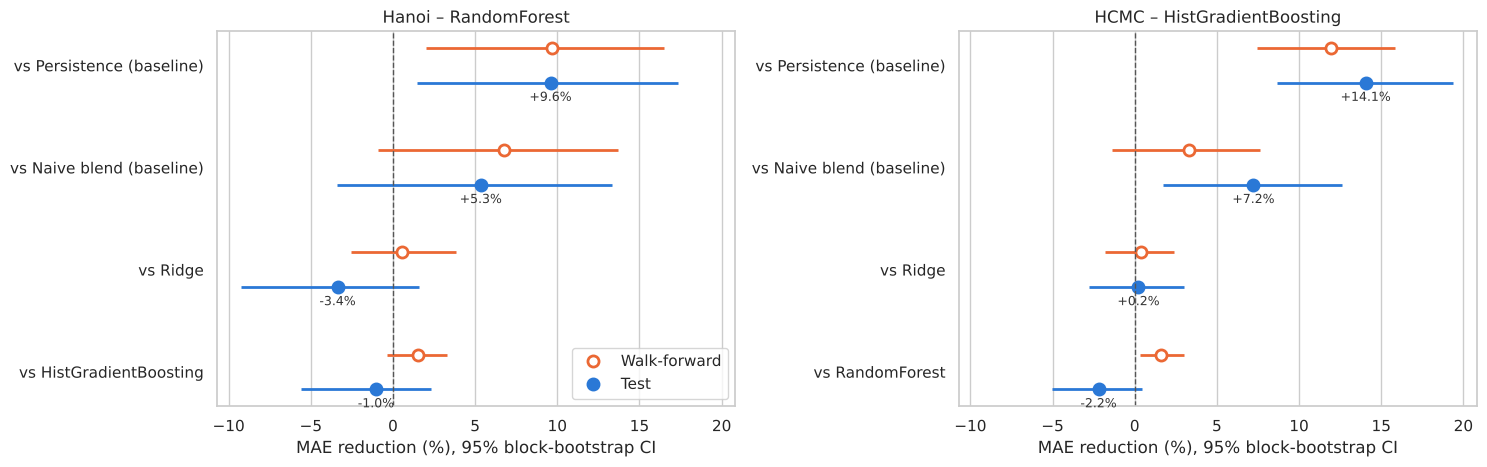

In [21]:
# Forest plot of the bootstrap confidence intervals
SET_STYLE = {'Walk-forward': {'color': '#eb6834', 'mfc': 'white', 'offset': -0.17},   # y axis is inverted: walk-forward on top
             'Test': {'color': '#2a78d6', 'mfc': '#2a78d6', 'offset': 0.17}}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharex=True)
for ax, city in zip(axes, CITY_FILES):
    labels = competitors(city)
    for set_name, st in SET_STYLE.items():
        sub = boot[(boot.city == city) & (boot.set == set_name)].set_index('vs').loc[labels]
        y = np.arange(len(labels)) + st['offset']
        ax.hlines(y, sub['ci_low'] * 100, sub['ci_high'] * 100, color=st['color'], lw=2)
        ax.plot(sub['gain'] * 100, y, 'o', ms=8, color=st['color'], mfc=st['mfc'], mew=2, label=set_name)
        if set_name == 'Test':
            for yi, g in zip(y, sub['gain']):
                ax.annotate(f'{g:+.1%}', (g * 100, yi), xytext=(0, -13), textcoords='offset points',
                            ha='center', fontsize=9, color='#333333')
    ax.axvline(0, color='#555555', ls='--', lw=1)
    ax.set_yticks(range(len(labels)), [f'vs {l}' for l in labels])
    ax.invert_yaxis()
    ax.set(title=f'{city} – {best_model[city]}', xlabel='MAE reduction (%), 95% block-bootstrap CI')
    ax.grid(axis='y', visible=False)
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

_(Pending: written after the notebook is run on the current data.)_

### 4.4. Forecast vs. actual
**Figure 8 – First 14 days of the Test set:** actual values, the Naive blend baseline and the best model of each city (chosen by walk-forward validation)
(the time axis is the **forecast** time, i.e. $t + 24h$).

Hanoi – first 14 days of Test (337 hours): MAE Naive blend 12.42 vs RandomForest 10.99 | std of forecast 7.2 vs actual 15.5 µg/m³
HCMC – first 14 days of Test (337 hours): MAE Naive blend 10.85 vs HistGradientBoosting 11.45 | std of forecast 5.5 vs actual 18.5 µg/m³


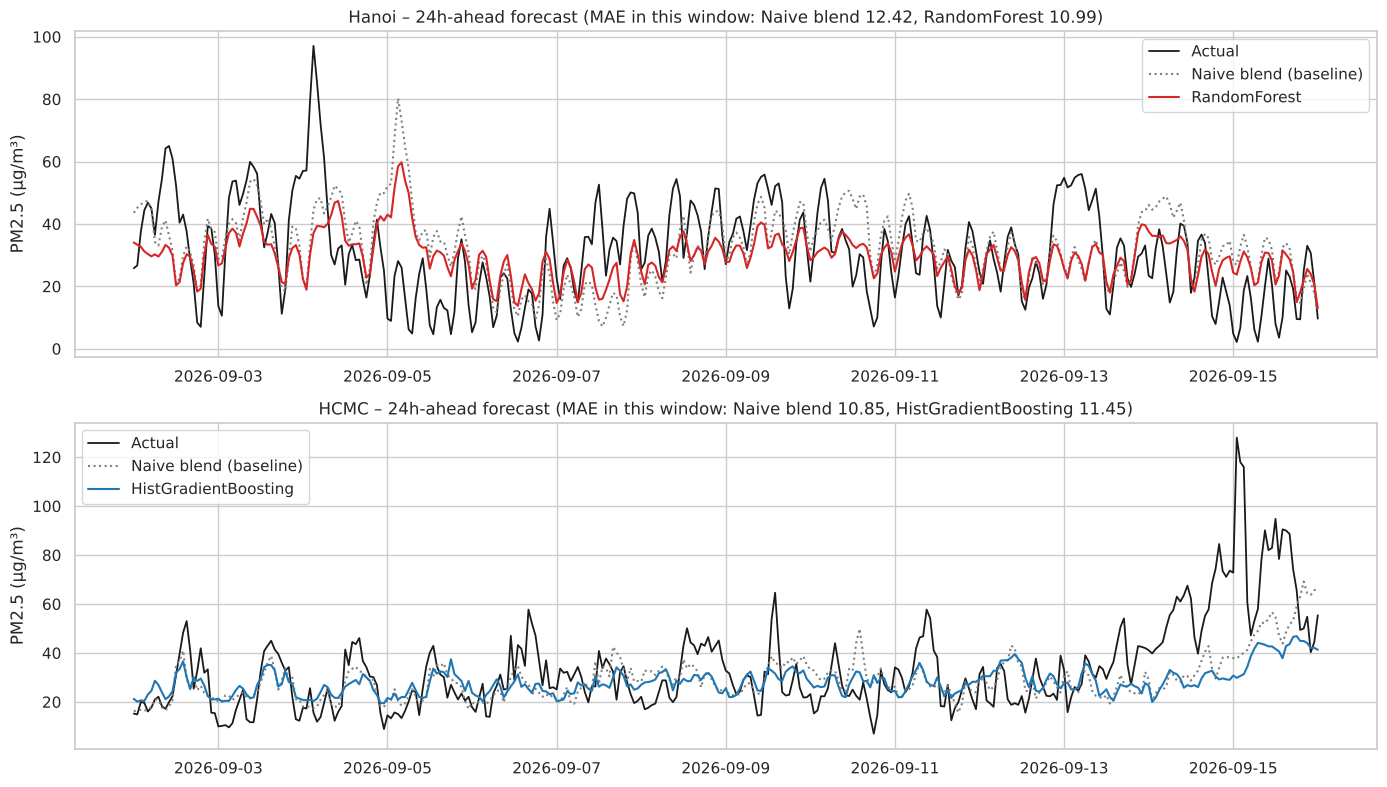

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, (city, f) in zip(axes, forecasters.items()):
    p = f.test_predictions
    w = p.loc[: p.index.min() + pd.Timedelta(days=14)]
    target_time = w.index + pd.Timedelta(hours=HORIZON)
    ax.plot(target_time, w['actual'], color='k', lw=1.3, label='Actual')
    ax.plot(target_time, w['Naive blend (baseline)'], color='gray', ls=':', label='Naive blend (baseline)')
    ax.plot(target_time, w[best_model[city]], color=CITY_COLORS[city], label=best_model[city])
    mae_blend = mean_absolute_error(w['actual'], w['Naive blend (baseline)'])
    mae_best = mean_absolute_error(w['actual'], w[best_model[city]])
    print(f'{city} – first 14 days of Test ({len(w)} hours): MAE Naive blend {mae_blend:.2f} vs {best_model[city]} {mae_best:.2f} | '
          f'std of forecast {w[best_model[city]].std():.1f} vs actual {w["actual"].std():.1f} µg/m³')
    ax.set(title=f'{city} – 24h-ahead forecast (MAE in this window: Naive blend {mae_blend:.2f}, {best_model[city]} {mae_best:.2f})',
           ylabel='PM2.5 (µg/m³)')
    ax.legend()
plt.tight_layout()
plt.show()

_(Pending: written after the notebook is run on the current data.)_

### 4.5. Error analysis
A regression problem has no direct confusion matrix, so we (1) analyze the error by **hour of day** (the error by **month** is the
walk-forward figure of Section 3.2), and
(2) put both the actual and the forecast PM2.5 into **concentration bands** defined by the US EPA 2024 PM2.5 breakpoints
(Good ≤ 9.0, Moderate 9.1–35.4, USG 35.5–55.4, Unhealthy 55.5–125.4, Very unhealthy and above ≥ 125.5 µg/m³) and build a
**band confusion matrix** — showing which band the model tends to confuse with which.

*Precision about the definition:* the official EPA AQI is computed from a **24-hour average** (or the NowCast for hourly reporting).
Here the breakpoints are applied to **hourly** concentrations, so these are "EPA concentration bands", **not** official AQI values.
As in the EPA rule, a concentration is first truncated to one decimal (e.g. 9.05 → 9.0 → Good) and then binned.

Hanoi Walk-forward: MAE by hour of the forecast time min 10.6 (h17) – max 13.8 (h6) | hours with < 20 samples (not shown): []
Hanoi Test: MAE by hour of the forecast time min 8.2 (h17) – max 13.8 (h6) | hours with < 20 samples (not shown): []
HCMC Walk-forward: MAE by hour of the forecast time min 7.5 (h19) – max 11.1 (h7) | hours with < 20 samples (not shown): []
HCMC Test: MAE by hour of the forecast time min 8.5 (h20) – max 13.8 (h4) | hours with < 20 samples (not shown): []


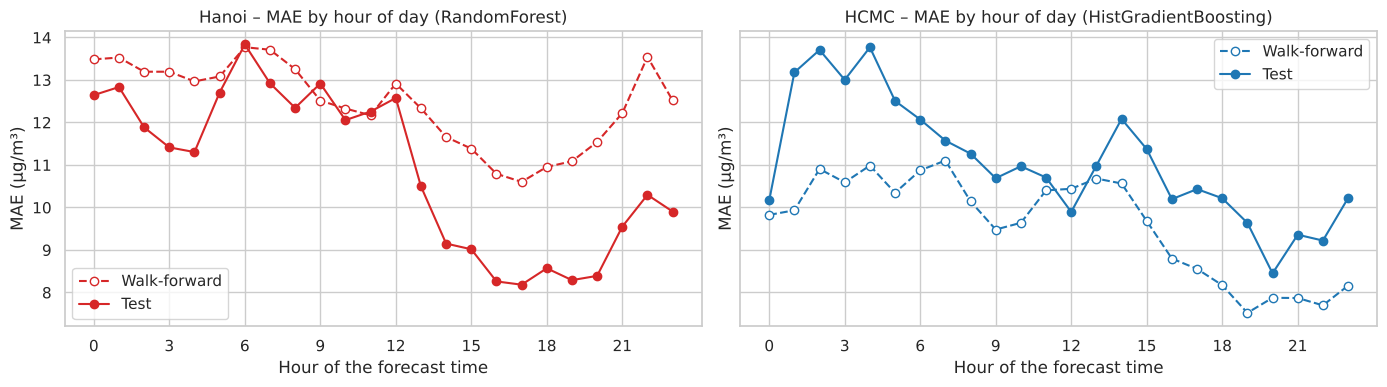

In [23]:
MIN_SAMPLES = 20   # hours of the day with fewer samples are not shown (too noisy)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (city, f) in zip(axes, forecasters.items()):
    for set_name, p, style in [('Walk-forward', f.wf_predictions, dict(ls='--', marker='o', mfc='white')),
                               ('Test', f.test_predictions, dict(ls='-', marker='o'))]:
        err = (p[best_model[city]] - p['actual']).abs()
        t = p.index + pd.Timedelta(hours=HORIZON)                  # forecast time
        hour_stats = err.groupby(t.hour).agg(['mean', 'size'])
        by_hour = hour_stats.loc[hour_stats['size'] >= MIN_SAMPLES, 'mean']
        ax.plot(by_hour.index, by_hour, color=CITY_COLORS[city], label=set_name, **style)
        print(f'{city} {set_name}: MAE by hour of the forecast time min {by_hour.min():.1f} (h{by_hour.idxmin()}) – '
              f'max {by_hour.max():.1f} (h{by_hour.idxmax()}) | hours with < {MIN_SAMPLES} samples (not shown): '
              f'{hour_stats.index[hour_stats["size"] < MIN_SAMPLES].tolist()}')
    ax.set(title=f'{city} – MAE by hour of day ({best_model[city]})', xlabel='Hour of the forecast time',
           ylabel='MAE (µg/m³)', xticks=range(0, 24, 3))
    ax.legend()
plt.tight_layout()
plt.show()

Hanoi: correct EPA band on the walk-forward forecasts 61.0% (for comparison with Test below)
Hanoi Test: correct EPA band 59.3% | within ±1 band: 96.7%
Predicted        Good  Moderate  USG  Unhealthy  Very unhealthy+
Actual                                                          
Good                0       126    5          1                0
Moderate            0       862  102          9                0
USG                 0       271  145         39                0
Unhealthy           0        44  125         46                0
Very unhealthy+     0         0    0          0                0

HCMC: correct EPA band on the walk-forward forecasts 66.9% (for comparison with Test below)
HCMC Test: correct EPA band 60.5% | within ±1 band: 96.8%
Predicted        Good  Moderate  USG  Unhealthy  Very unhealthy+
Actual                                                          
Good                0        36    1          0                0
Moderate            0       866  201          1

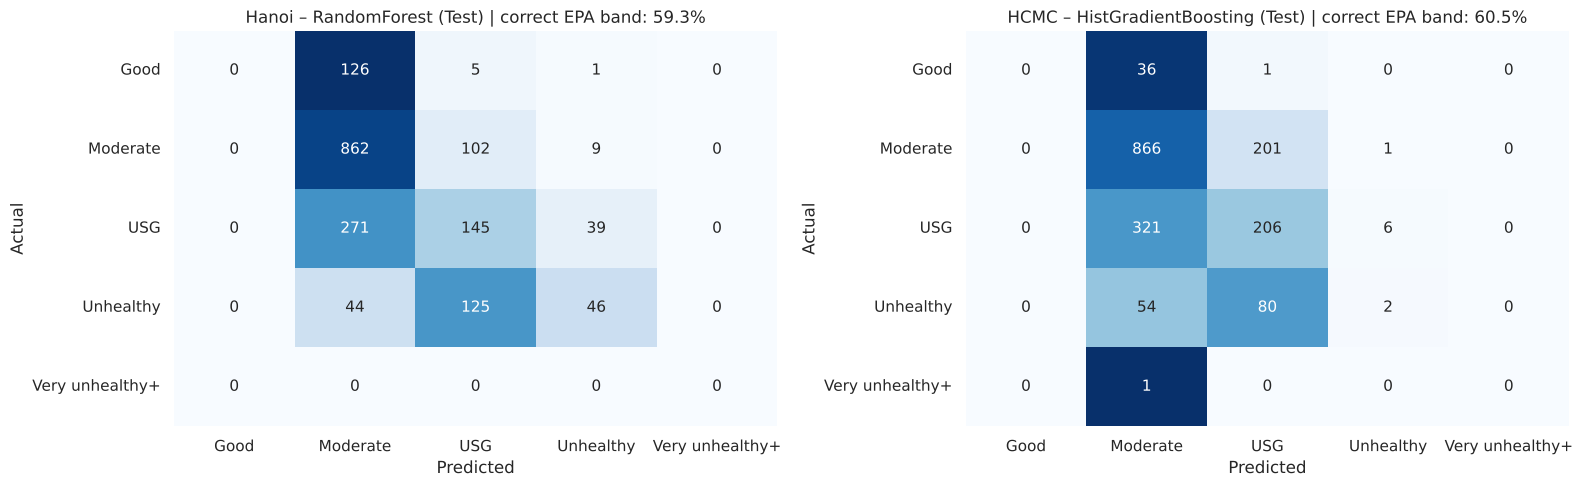

In [24]:
EPA_BINS = [-np.inf, 9.0, 35.4, 55.4, 125.4, np.inf]      # right-closed: (-inf, 9.0], (9.0, 35.4], ...
EPA_LABELS = ['Good', 'Moderate', 'USG', 'Unhealthy', 'Very unhealthy+']


def to_epa_band(values):
    """Truncate to 0.1 µg/m³ (EPA rule), then map each hourly PM2.5 value to its EPA concentration band."""
    truncated = np.floor(np.asarray(values, dtype=float) * 10) / 10
    return pd.cut(pd.Series(truncated), bins=EPA_BINS, labels=EPA_LABELS)


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (city, f) in zip(axes, forecasters.items()):
    wf = f.wf_predictions
    wf_acc = (to_epa_band(wf['actual']) == to_epa_band(wf[best_model[city]])).mean()
    print(f'{city}: correct EPA band on the walk-forward forecasts {wf_acc:.1%} (for comparison with Test below)')
    p = f.test_predictions
    actual_lvl, pred_lvl = to_epa_band(p['actual']), to_epa_band(p[best_model[city]])
    cm = pd.crosstab(actual_lvl, pred_lvl, rownames=['Actual'], colnames=['Predicted'], dropna=False)
    cm = cm.reindex(index=EPA_LABELS, columns=EPA_LABELS, fill_value=0)
    cm_norm = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    sns.heatmap(cm_norm, annot=cm.values, fmt='d', cmap='Blues', cbar=False, ax=ax)
    acc = (actual_lvl == pred_lvl).mean()
    ax.set_title(f'{city} – {best_model[city]} (Test) | correct EPA band: {acc:.1%}')
    print(f'{city} Test: correct EPA band {acc:.1%} | within ±1 band: '
          f'{(abs(actual_lvl.cat.codes - pred_lvl.cat.codes) <= 1).mean():.1%}')
    print(cm, end='\n\n')
plt.tight_layout()
plt.show()

*USG = Unhealthy for Sensitive Groups (35.5–55.4 µg/m³).*

_(Pending: written after the notebook is run on the current data.)_

### 4.6. Feature importance (permutation importance)
Measures how much the Test MAE increases when each original feature of the best model is randomly shuffled.
*Caveat:* the PM2.5 lag/rolling features are strongly correlated, so shuffling one of them hurts less than its real
contribution (the others carry the same information) — the importance of the "PM2.5 history" group is spread over several features.

Hanoi – top 5: {'pm25_lag_0': 2.37, 'surface_pressure': 0.17, 'rain_24h': 0.17, 'wind_speed_10m': 0.12, 'pm25_lag_1': 0.11}


HCMC – top 5: {'pm25_lag_0': 0.64, 'hour_cos': 0.24, 'rain_24h': 0.1, 'pm25_roll_mean_24': 0.06, 'surface_pressure': 0.05}


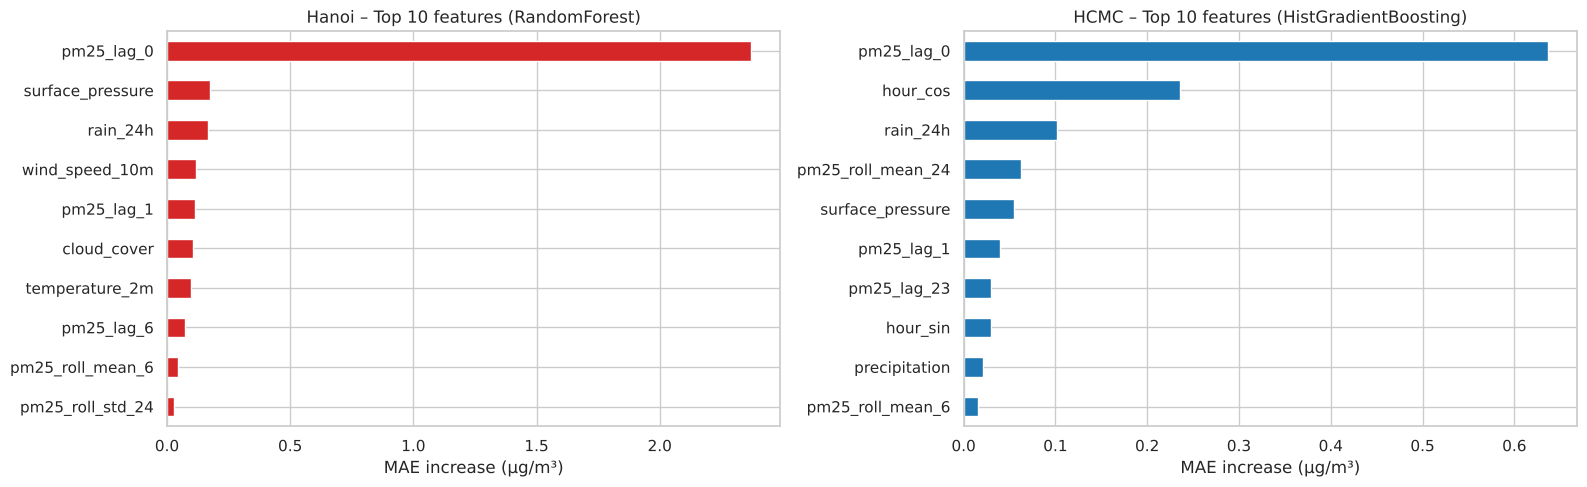

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (city, f) in zip(axes, forecasters.items()):
    model = f.models[best_model[city]]
    imp = permutation_importance(model, f.test[FEATURES], f.test[TARGET], n_repeats=5,
                                 scoring='neg_mean_absolute_error', random_state=RANDOM_STATE)
    s = pd.Series(imp.importances_mean, index=FEATURES).nlargest(10).sort_values()
    s.plot.barh(ax=ax, color=CITY_COLORS[city])
    print(f'{city} – top 5:', s[::-1].head(5).round(2).to_dict())
    ax.set(title=f'{city} – Top 10 features ({best_model[city]})', xlabel='MAE increase (µg/m³)')
plt.tight_layout()
plt.show()

Because single-feature importance is diluted by correlated features, we also shuffle **whole groups** of features together
(grouped permutation importance): PM2.5 history, weather (including wind sector) and calendar (hour, season, day of week).

In [26]:
FEATURE_GROUPS = {'PM2.5 history': PM_FEATURES,
                  'Weather': WEATHER_FEATURES + ['wind_sector'],
                  'Calendar': CYCLIC_FEATURES + ['season', 'day_of_week']}


def group_importance(model, X, y, groups, n_repeats=10, seed=RANDOM_STATE):
    """Mean MAE increase when all columns of a group are shuffled together (same row permutation)."""
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(y, model.predict(X))
    result = {}
    for name, cols in groups.items():
        deltas = []
        for _ in range(n_repeats):
            Xs = X.copy()
            Xs[cols] = X[cols].values[rng.permutation(len(X))]
            deltas.append(mean_absolute_error(y, model.predict(Xs)) - base)
        result[name] = np.mean(deltas)
    return result


group_imp = pd.DataFrame({city: group_importance(f.models[best_model[city]], f.test[FEATURES], f.test[TARGET], FEATURE_GROUPS)
                          for city, f in forecasters.items()})
print('Grouped importance (MAE increase, µg/m³):', group_imp.round(2).to_dict())
display(group_imp.round(2))

Grouped importance (MAE increase, µg/m³): {'Hanoi': {'PM2.5 history': 3.82, 'Weather': 0.95, 'Calendar': -0.06}, 'HCMC': {'PM2.5 history': 1.55, 'Weather': 0.17, 'Calendar': 0.26}}


,Hanoi,HCMC
PM2.5 history,3.82,1.55
Weather,0.95,0.17
Calendar,-0.06,0.26


_(Pending: written after the notebook is run on the current data.)_

### 4.7. Inference demo: `predict_next`
Takes the hourly observation history up to time $t$ and returns the PM2.5 forecast at $t + 24h$ together with its EPA concentration band.
Demo: we use a history ending 24 hours before the last available observation, then compare with the known actual value.

In [27]:
def predict_next(city, history):
    """history: hourly DataFrame (same columns as the cleaned data), ending at time t."""
    model = forecasters[city].models[best_model[city]]
    x_last = build_features(history, city).iloc[[-1]]
    value = float(model.predict(x_last[FEATURES])[0])
    return {'city': city, 'model': best_model[city],
            'forecast_time': x_last.index[0] + pd.Timedelta(hours=HORIZON),
            'pm25_forecast': round(value, 1), 'epa_band': str(to_epa_band([value])[0])}


demo_rows = []
for city, df in clean.items():
    t_end = df['pm25_raw'].last_valid_index() - pd.Timedelta(hours=HORIZON)
    history = df.loc[t_end - pd.Timedelta(days=7): t_end]
    res = predict_next(city, history)
    actual = df.loc[res['forecast_time'], 'pm25_raw']
    res.update({'pm25_actual': round(float(actual), 1), 'epa_band_actual': str(to_epa_band([actual])[0])})
    demo_rows.append(res)
display(pd.DataFrame(demo_rows))

,city,model,forecast_time,pm25_forecast,epa_band,pm25_actual,epa_band_actual
0,Hanoi,RandomForest,2026-11-14 22:00:00,31.2,Moderate,55.3,USG
1,HCMC,HistGradientBoosting,2026-11-14 22:00:00,25.0,Moderate,23.7,Moderate


### 4.8. Conclusions, limitations and future work

_(Pending: written after the notebook is run on the current data.)_